### Biological annotation

**Biological annotation of developmental reference PCs, lineage and malignant directions.**

This produces Heatmaps suitable for Supplementary Figs. S8-S11

In [6]:
import os, json
import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import re

from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import scanpy as sc
import seaborn as sns
import gseapy as gp

import torch
from transformers import BertForMaskedLM

In [7]:
commonpathlocal = "/home/jfpoyatos/Work/MNCN_24_25/A - plasticity - What's next/"
commonpath = "scripts/data/Mouse/"
saved_dir = os.path.join(commonpathlocal, commonpath,"models/bert_dev_8/")
msigdb_dir= os.path.join(commonpathlocal, commonpath,"msigdb_mouse_gmt/")

OUTDIR = os.path.join(commonpathlocal, commonpath,"annotation/")
OUTDIR_c = os.path.join(commonpathlocal, commonpath,"annotation_malignant_residual_axes/")

>*Some required functions*

In [8]:
# .. expression matrix
def get_expression_matrix(adata, layer=None):
    if layer is not None:
        X = adata.layers[layer]
    else:
        X = adata.X
    # If X is a scipy sparse matrix (sp.issparse), convert it to CSR format with tocsr() and return that. 
    # CSR is efficient for row-slicing and many downstream operations.
    if sp.issparse(X):
        return X.tocsr()

    # if X is not sparse, convert it to a NumPy array and return it.
    return np.asarray(X)

> Learned model

In [9]:
# loads a pretrained BERT model for masked language modeling
# config.json defines the model architecture and settings
# model.safetensors contains the trained weights
model = BertForMaskedLM.from_pretrained(saved_dir)

meta_path = os.path.join(saved_dir, "vocab_meta.json")
with open(meta_path) as f:
    meta = json.load(f)

# Meta is a dictionary with the following keys
print('keys of meta dictionary -> ',meta.keys())

required = ["gene2id","PAD_ID","CLS_ID","SEP_ID","MASK_ID","DEV_DOM_ID","CANCER_DOM_ID","vocab_size"]
missing = [k for k in required if k not in meta]
assert not missing, f"vocab_meta.json missing keys: {missing}"

# unpacking the dictionary into variables.
gene2id       = meta["gene2id"]
PAD_ID        = meta["PAD_ID"]
CLS_ID        = meta["CLS_ID"]
SEP_ID        = meta["SEP_ID"]
MASK_ID       = meta["MASK_ID"]
DEV_DOM_ID    = meta["DEV_DOM_ID"]
CANCER_DOM_ID = meta["CANCER_DOM_ID"]
vocab_size    = meta["vocab_size"]

# Sanity checks (fail fast)
assert model.config.vocab_size == vocab_size, (
    f"Model vocab_size ({model.config.vocab_size}) != meta vocab_size ({vocab_size}). "
    "You likely loaded mismatched checkpoint + vocab."
)

# Ensure special IDs are in range and distinct (no two special tokens share the same ID)
specials = [PAD_ID, CLS_ID, SEP_ID, MASK_ID, DEV_DOM_ID, CANCER_DOM_ID]
assert len(set(specials)) == len(specials), "Some special token IDs collide."
assert all(0 <= x < vocab_size for x in specials), "A special token ID is out of vocab range."

keys of meta dictionary ->  dict_keys(['gene2id', 'PAD_ID', 'CLS_ID', 'SEP_ID', 'MASK_ID', 'DEV_DOM_ID', 'CANCER_DOM_ID', 'vocab_size'])


In [10]:
X_tokens_eval = np.load(os.path.join(saved_dir, "X_tokens.npy"))
X_attn_eval   = np.load(os.path.join(saved_dir, "X_attn.npy"))
domain_eval   = np.load(os.path.join(saved_dir, "domain.npy"))

>CLS embeddings

In [11]:
# This disables gradient tracking.You’re doing inference, not training. Saves memory
@torch.no_grad()

def cls_embeddings(model, Xt, At, batch_size=16):
    """
    Compute CLS embeddings for a set of tokenized cells.

    Xt: numpy array of shape (N, L) with token IDs
    At: numpy array of shape (N, L) with attention masks
    batch_size: how many cells to process at once (for memory reasons)

    Returns:
      CLS: numpy array of shape (N, H)
           where H = hidden size of the BERT model.
           Each row is the CLS embedding for one cell.
    """
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    # Why eval() matters: Disables dropout. Makes outputs deterministic
    # Dropout. During training, the model randomly “ignores” some neurons each time it processes input.
    model.eval() 

    embs = []

    N = Xt.shape[0]
    for i in range(0, N, batch_size):
        # Take a minibatch of cells, B
        x_batch = Xt[i:i+batch_size]
        a_batch = At[i:i+batch_size]

        # Convert to torch tensors on the right device
        x = torch.as_tensor(x_batch, dtype=torch.long, device=device)  # (B, L)
        a = torch.as_tensor(a_batch, dtype=torch.long, device=device)  # (B, L)

        # Run only the BERT encoder
        out = model.bert(input_ids=x,attention_mask=a,output_hidden_states=False,return_dict=True)

        # out.last_hidden_state: (B, L, H)
        # Your sequence is [DOM], [CLS], genes..., [SEP],
        # so CLS is at position index 1.
        cls_batch = out.last_hidden_state[:, 1, :]   # (B, H)

        # Move to CPU and store
        embs.append(cls_batch.cpu())

    # Concatenate all batches -> (N, H)
    CLS = torch.cat(embs, dim=0).numpy()
    return CLS


# Compute CLS embeddings for eval set ----------
CLS = cls_embeddings(model, X_tokens_eval, X_attn_eval, batch_size=16)  # (N, H)

# domain_eval: 0 = development, 1 = cancer
is_dev = (domain_eval == 0)
is_can = (domain_eval == 1)

In [12]:
# .. specific of each domain
X_dev = CLS[is_dev]   # (n_dev, H)
X_can = CLS[is_can]   # (n_can, H)
del CLS

print("X_dev:", X_dev.shape)
print("X_can:", X_can.shape)

X_dev: (34760, 256)
X_can: (28131, 256)


In [13]:
# Developmental data
in_dev    = os.path.join(commonpathlocal,commonpath, "dev/A_dev_aln3.h5ad")
A_dev_aln    = sc.read_h5ad(in_dev)

In [14]:
# Developmental labels

def map_state(x):
    if x == "foregut_other":
        return "foregut"
    elif x == "pancreas_ductal_proxy":
        return "ductal"
    elif x == "pancreas_acinar":
        return "acinar"
    elif x == "biliary":
        return "biliary"
    elif x == "pancreas_islet":
        return "islet"
    else:
        return "other"

A_dev_aln.obs["dev_clean"] = A_dev_aln.obs["endo_category"].map(map_state)

>Developmental PCA

In [15]:
# Center using DEV mean
mu = X_dev.mean(axis=0)  # column-wise mean
Xd = X_dev - mu

In [16]:
# .. developmental PCA
pca = PCA(n_components=75)  # enough to cover ~98% variance
Xd_pca = pca.fit_transform(Xd)
print("Xd_pca dimensions: ",Xd_pca.shape)
# .. basis
basis = pca.components_.T   # shape: embedding_dim x k
print('basis shape:',basis.shape)

print("DEV variance explained by first 75 PCs:", 
      pca.explained_variance_ratio_.sum())
print('PCA projection dims:',Xd_pca.shape)
print('')

Xd_pca dimensions:  (34760, 75)
basis shape: (256, 75)
DEV variance explained by first 75 PCs: 0.981794
PCA projection dims: (34760, 75)



**PC developmental subspace masked by specific lineages**


In [17]:
# .. subset data
mask = A_dev_aln.obs["dev_clean"].isin(["foregut", "ductal", "acinar", "biliary"])
labels_dev = A_dev_aln.obs["dev_clean"][mask].values

# ..
Xd_pca_sub = Xd_pca[mask]

print("Xd_pca_sub dimensions: ",Xd_pca_sub.shape)
print("Labels_dev dimensions: ", labels_dev.shape)
print("unique labels: ", np.unique(labels_dev, return_counts=True))

Xd_pca_sub dimensions:  (13437, 75)
Labels_dev dimensions:  (13437,)
unique labels:  (array(['acinar', 'biliary', 'ductal', 'foregut'], dtype=object), array([3747, 1742, 4000, 3948]))


### 1. **Annotate the developmental reference axes biologically**

*Note: If adata and Xd_pca_sub are mismatched, all downstream gene correlations become meaningless.*

In [18]:
# Expression matrix and the CLS-derived developmental coordinates should be row-aligned
# Developmental labels to keep
DEV_STATES = ["foregut", "ductal", "acinar", "biliary"]

# Mask on the aligned developmental AnnData object
mask = A_dev_aln.obs["dev_clean"].isin(DEV_STATES).values

# Subset AnnData to match Xd_pca_sub
adata = A_dev_aln[mask].copy()
print(adata)

# Labels corresponding to Xd_pca_sub rows
labels_dev = A_dev_aln.obs["dev_clean"][mask].astype(str).values

# CLS/PCA coordinates from the masked language model developmental space
coords_dev = np.asarray(Xd_pca_sub)

print("adata shape:", adata.shape)
print("coords_dev shape:", coords_dev.shape)
print("labels shape:", labels_dev.shape)

assert adata.n_obs == coords_dev.shape[0]
assert adata.n_obs == len(labels_dev)

AnnData object with n_obs × n_vars = 13437 × 15376
    obs: 'cell_id', 'keep', 'day', 'embryo_id', 'experimental_batch', 'cell_id_base', 'major_trajectory', 'celltype_update', 'endo_category', 'day_meta', 'dev_state_pancreas', 'dev_state_union', 'dev_day', 'source_file', 'dev_tier', 'dev_clean'
    var: 'symbol'
adata shape: (13437, 15376)
coords_dev shape: (13437, 75)
labels shape: (13437,)


In [19]:
LINEAGE_COL = "dev_clean"

FOREGUT_LABEL = "foregut"
DUCTAL_LABEL = "ductal"
ACINAR_LABEL = "acinar"
BILIARY_LABEL = "biliary"

N_PCS_TO_ANNOTATE = 10
N_PCS_FOR_LINEAGE_DIRECTIONS = 75 

# Use None for adata.X.
# Use your normalized layer if available, for example:
# LAYER = "lognorm"
LAYER = None

# Pearson is fast and usually fine here.
# Spearman is slower but more rank-robust.
CORR_METHOD = "pearson"

**Mouse marker programs** (see also Results_MousePrograms.ipynb)

In [20]:
PROGRAMS_MOUSE = {
    "foregut_early_epithelial_identity": [
        "Sox2", "Sox9", "Foxa1", "Foxa2", "Hnf1b",
        "Krt8", "Krt18", "Epcam", "Cldn4"
    ],

    "ductal_differentiation": [
        "Krt19", "Krt7", "Sox9", "Cftr", "Muc1",
        "Mmp7", "Slc4a4", "Anxa4", "Cldn10", "Hnf1b"
    ],

    "acinar_differentiation": [
        "Prss1", "Prss2", "Cela2a", "Cela3b",
        "Cpa1", "Cpa2", "Cpb1", "Ctrb1", 
        "Reg1", "Reg2", "Pnlip", "Clps", "Amy2a5"
    ],

    "biliary_like_differentiation": [
        "Krt7", "Krt19", "Sox9", "Epcam", "Muc1",
        "Tff1", "Tff2", "Slc4a2", "Anxa4",
        "Cldn4", "Cldn10", "Hnf1b"
    ],

    "proliferation_cell_cycle": [
        "Mki67", "Top2a", "Pcna", "Mcm2", "Mcm3", "Mcm4",
        "Mcm5", "Mcm6", "Mcm7", "Cdk1", "Ccnb1",
        "Ccnb2", "Ube2c", "Birc5"
    ],

    "morphogenesis_epithelial_maturation": [
        "Epcam", "Krt8", "Krt18", "Krt19", "Cdh1",
        "Cldn3", "Cldn4", "Ocln", "Tjp1",
        "Itga6", "Lamc2"
    ],

    "secretory_digestive_enzyme_program": [
        "Prss1", "Prss2", "Cela2a", "Cela3b",
        "Cpa1", "Cpa2", "Cpb1", "Ctrb1", 
        "Pnlip", "Clps", "Amy2a5" 
    ],

    "progenitor_fetal_like_program": [
        "Sox9", "Prom1", "Aldh1a1", "Aldh1a3",
        "Nes", "Tff1", "Tff2",
        "S100a10", "Lgals1", "Vim"
    ],
    
    "neuroendocrine_like_peptide_hormone": [
        "Chga", "Chgb", "Scg2", "Scg3", "Scg5",
        "Snap25", "Syt1", "Syt4", "Syt13", "Rab3a", "Rab3b",
        "Neurod1", "Fev", "Isl1", "Pax6", "Nkx2-2",
        "Gip", "Cck", "Gast", "Tph1", "Penk", "Resp18"
    ],
}

**Marker coverage** (I used this to identify which genes in the initiall call of the programs were not present)

In [21]:
# .. i used this report to select programs with genes available in adata
def report_program_marker_coverage(adata, programs):
    rows = []
    gene_names = set(adata.var['symbol'])

    for program, genes in programs.items():
        present = [g for g in genes if g in gene_names]
        missing = [g for g in genes if g not in gene_names]

        rows.append({
            "program": program,
            "n_total": len(genes),
            "n_present": len(present),
            "fraction_present": len(present) / len(genes),
            "present_genes": ", ".join(present),
            "missing_genes": ", ".join(missing),
        })

    return pd.DataFrame(rows).sort_values("fraction_present")

In [22]:
marker_coverage = report_program_marker_coverage(adata, PROGRAMS_MOUSE)
marker_coverage.to_csv(os.path.join(OUTDIR, "mouse_program_marker_coverage.csv"),index=False)
marker_coverage

,program,n_total,n_present,fraction_present,present_genes,missing_genes
0,foregut_early_epithelial_identity,9,9,1.0,"Sox2, Sox9, Foxa1, Foxa2, Hnf1b, Krt8, Krt18, ...",
1,ductal_differentiation,10,10,1.0,"Krt19, Krt7, Sox9, Cftr, Muc1, Mmp7, Slc4a4, A...",
2,acinar_differentiation,13,13,1.0,"Prss1, Prss2, Cela2a, Cela3b, Cpa1, Cpa2, Cpb1...",
3,biliary_like_differentiation,12,12,1.0,"Krt7, Krt19, Sox9, Epcam, Muc1, Tff1, Tff2, Sl...",
4,proliferation_cell_cycle,14,14,1.0,"Mki67, Top2a, Pcna, Mcm2, Mcm3, Mcm4, Mcm5, Mc...",
5,morphogenesis_epithelial_maturation,11,11,1.0,"Epcam, Krt8, Krt18, Krt19, Cdh1, Cldn3, Cldn4,...",
6,secretory_digestive_enzyme_program,11,11,1.0,"Prss1, Prss2, Cela2a, Cela3b, Cpa1, Cpa2, Cpb1...",
7,progenitor_fetal_like_program,10,10,1.0,"Sox9, Prom1, Aldh1a1, Aldh1a3, Nes, Tff1, Tff2...",
8,neuroendocrine_like_peptide_hormone,22,22,1.0,"Chga, Chgb, Scg2, Scg3, Scg5, Snap25, Syt1, Sy...",


**Gene axis correlations routines**

Correlate gene expression with a CLS-derived developmental coordinate.\
**Important**: The axis is not a *gene-expression* PC. It is a coordinate in the masked-language-model CLS PCA space.\
(axis_values might be something like ResCLS_PC1, ...)

In [23]:
def gene_axis_correlations(adata, axis_values, layer=None, method="pearson"):
    
    X = get_expression_matrix(adata, layer=layer)
    y = np.asarray(axis_values).astype(float)

    valid = np.isfinite(y)
    X = X[valid, :]
    y = y[valid]

    #genes = np.asarray(adata.var_names)
    genes = np.asarray(adata.var['symbol'])

    # .. correlation between y and each column of X; computed depending on X being sparse
    # .. we center the corresponding vectors
    if method == "pearson":
        y_centered = y - y.mean()
        y_sd = y_centered.std(ddof=1) # unbiased standard deviation estimate

        if y_sd == 0:
            raise ValueError("Axis has zero variance.")

        if sp.issparse(X):
            x_mean = np.asarray(X.mean(axis=0)).ravel()
            X_centered = X - x_mean

            numerator = np.asarray(X_centered.T @ y_centered).ravel()
            x_var = (np.asarray(X_centered) ** 2).sum(axis=0).ravel() / (X_centered.shape[0] - 1)
            x_sd = np.sqrt(x_var)
        else:
            x_mean = X.mean(axis=0)
            X_centered = X - x_mean

            numerator = X_centered.T @ y_centered
            x_sd = X_centered.std(axis=0, ddof=1)

        denom = (X.shape[0] - 1) * x_sd * y_sd

        r = np.divide(numerator,denom,out=np.zeros_like(numerator, dtype=float),where=denom != 0)

    elif method == "spearman":
        warnings.warn("Spearman correlation can be slow for large datasets.")

        if sp.issparse(X):
            X = X.toarray()

        r = []
        for j in range(X.shape[1]):
            value = spearmanr(X[:, j], y, nan_policy="omit").correlation
            if np.isnan(value):
                value = 0
            r.append(value)

        r = np.asarray(r)

    else:
        raise ValueError("method must be 'pearson' or 'spearman'.")

    out = pd.DataFrame({"gene": genes,"correlation": r,"abs_correlation": np.abs(r)})

    return out.sort_values("abs_correlation", ascending=False)

Developmental lineage directions

**Lineage coordinates**\
Define lineage direction in CLS-derived developmental PCA space.\
Direction: centroid(end_label) - centroid(start_label)\
Each cell gets a scalar coordinate by projection onto this vector.

In [24]:
def get_lineage_direction_coordinates(coords,labels,start_label,end_label,n_dims=30):
    labels = np.asarray(labels).astype(str)

    start_mask = labels == str(start_label)
    end_mask = labels == str(end_label)

    if start_mask.sum() == 0:
        raise ValueError(f"No cells found for start label: {start_label}")

    if end_mask.sum() == 0:
        raise ValueError(f"No cells found for end label: {end_label}")

    # coords is already Xd_pca_sub
    X = coords[:, :n_dims]

    # centroids in developmental subspace
    start_centroid = X[start_mask, :].mean(axis=0)
    end_centroid = X[end_mask, :].mean(axis=0)

    # lineages direction
    direction = end_centroid - start_centroid
    norm = np.linalg.norm(direction)
    if norm == 0:
        raise ValueError(f"Zero-length direction from {start_label} to {end_label}")
    unit_direction = direction / norm

    # projection
    # of developmental cells on lineage directions
    projection = (X - start_centroid) @ unit_direction

    return projection, unit_direction, start_centroid, end_centroid

**Score curated marker programs by average expression of present genes.**

In [25]:
def score_programs(adata, programs, layer=None, min_genes=2):
    
    X = get_expression_matrix(adata, layer=layer)

    gene_to_idx = {
        #gene: idx for idx, gene in enumerate(adata.var_names)
        gene: idx for idx, gene in enumerate(adata.var['symbol'])
    }

    scores = {}

    for program, gene_list in programs.items():
        present = [g for g in gene_list if g in gene_to_idx]

        if len(present) < min_genes:
            print(f"Skipping {program}: only {len(present)} marker(s) found.")
            continue

        idx = [gene_to_idx[g] for g in present]

        if sp.issparse(X):
            score = np.asarray(X[:, idx].mean(axis=1)).ravel()
        else:
            score = X[:, idx].mean(axis=1)

        scores[program] = score

    return pd.DataFrame(scores, index=adata.obs_names)

In [26]:
# Which biological programs increase or decrease along each learned axis?
def correlate_program_scores(axis_values_dict, program_scores):
    rows = []

    for axis_name, axis_values in axis_values_dict.items():
        for program in program_scores.columns:
            r = spearmanr(axis_values,program_scores[program],nan_policy="omit").correlation

            rows.append({
                "axis": axis_name,
                "program": program,
                "spearman_r": r,
                "abs_spearman_r": abs(r),
            })

    return pd.DataFrame(rows).sort_values(
        ["axis", "abs_spearman_r"],
        ascending=[True, False]
    )

These functions *ABOVE* now use Xd_pca_sub directly

some checking

In [27]:
print("coords_dev shape:", coords_dev.shape)
print("Number of dimensions available:", coords_dev.shape[1])

if coords_dev.shape[1] < max(N_PCS_TO_ANNOTATE, N_PCS_FOR_LINEAGE_DIRECTIONS):
    raise ValueError(
        f"Xd_pca_sub has only {coords_dev.shape[1]} dimensions, but requested "
        f"{max(N_PCS_TO_ANNOTATE, N_PCS_FOR_LINEAGE_DIRECTIONS)}."
    )

coords_dev shape: (13437, 75)
Number of dimensions available: 75


In [28]:
# Inspect variance explained by CLS PCA
# Original PCA object is still available as 'pca'

if "pca" in globals():
    var_df = pd.DataFrame({
        "component": [f"CLS_PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "cumulative_variance": np.cumsum(pca.explained_variance_ratio_),
    })

    display(var_df.head(20))

    var_df.to_csv(os.path.join(OUTDIR, "cls_pca_explained_variance.csv"),index=False) # False:not to write the dataset index 
else:
    print("No object named `pca` found. Skipping explained variance table.")

,component,explained_variance_ratio,cumulative_variance
0,CLS_PC1,0.057240,0.057240
1,CLS_PC2,0.053214,0.110454
2,CLS_PC3,0.046209,0.156663
3,CLS_PC4,0.042415,0.199078
4,CLS_PC5,0.040602,0.239681
5,CLS_PC6,0.037716,0.277397
6,CLS_PC7,0.036579,0.313975
7,CLS_PC8,0.035537,0.349512
8,CLS_PC9,0.034118,0.383630
9,CLS_PC10,0.033083,0.416714


> Annotate top CLS develomental PCs

In [29]:
# two Python dictionaries
axis_values = {}
axis_gene_tables = {}

for pc_idx in range(N_PCS_TO_ANNOTATE):
    axis_name = f"CLS_devPC{pc_idx + 1}"
    axis_coord = coords_dev[:, pc_idx]

    axis_values[axis_name] = axis_coord

    corr_df = gene_axis_correlations(adata,axis_coord,layer=LAYER,method=CORR_METHOD)

    corr_df["axis"] = axis_name
    corr_df["axis_type"] = "CLS_embedding_PC"

    axis_gene_tables[axis_name] = corr_df

    corr_df.to_csv(os.path.join(OUTDIR,"axis_gene_correlations",f"{axis_name}_gene_correlations.csv"),index=False,)
    corr_df.head(100).to_csv(os.path.join(OUTDIR,"top_genes",f"{axis_name}_top_100_genes.csv"),index=False,)
    print(f"{axis_name}_gene_correlations.csv")
    print(f"{axis_name}_top_100_genes.csv")

print("")
print(f"Annotated CLS_PC1-CLS_PC{N_PCS_TO_ANNOTATE}")

CLS_devPC1_gene_correlations.csv
CLS_devPC1_top_100_genes.csv
CLS_devPC2_gene_correlations.csv
CLS_devPC2_top_100_genes.csv
CLS_devPC3_gene_correlations.csv
CLS_devPC3_top_100_genes.csv
CLS_devPC4_gene_correlations.csv
CLS_devPC4_top_100_genes.csv
CLS_devPC5_gene_correlations.csv
CLS_devPC5_top_100_genes.csv
CLS_devPC6_gene_correlations.csv
CLS_devPC6_top_100_genes.csv
CLS_devPC7_gene_correlations.csv
CLS_devPC7_top_100_genes.csv
CLS_devPC8_gene_correlations.csv
CLS_devPC8_top_100_genes.csv
CLS_devPC9_gene_correlations.csv
CLS_devPC9_top_100_genes.csv
CLS_devPC10_gene_correlations.csv
CLS_devPC10_top_100_genes.csv

Annotated CLS_PC1-CLS_PC10


**Inspect top genes for CLS PCs**

In [32]:
for axis_name, corr_df in axis_gene_tables.items():
    print("\n" + "-" * 20)
    print(axis_name)

    print("\nTop positive genes:")
    display(corr_df.sort_values("correlation", ascending=False).head(20)[["gene", "correlation"]]
    )

    print("Top negative genes:")
    display(corr_df.sort_values("correlation", ascending=True).head(20)[["gene", "correlation"]])


--------------------
CLS_devPC1

Top positive genes:


,gene,correlation
15092,Gm29543,0.020057
4889,4930426L09Rik,0.019258
4359,Muc2,0.019237
14708,Gm5784,0.018776
10539,9930038B18Rik,0.018533
1193,Retn,0.018418
14738,Gm3336,0.017854
12177,E130116L18Rik,0.017543
12855,Myh13,0.017399
12110,A730061H03Rik,0.017332


Top negative genes:


,gene,correlation
7403,Tcf12,-0.189008
9728,Rere,-0.188659
12318,Ankrd17,-0.182711
6436,Exoc4,-0.180925
4444,Pard3,-0.180887
5520,Fubp1,-0.180607
9572,Fndc3b,-0.179958
678,Hnrnpa2b1,-0.179896
1654,Ncor1,-0.176596
13438,Afdn,-0.175042



--------------------
CLS_devPC2

Top positive genes:


,gene,correlation
13618,Serpinh1,0.041714
5680,Ambp,0.036780
2362,Mxra7,0.035609
9329,Susd4,0.032821
8218,Grip1,0.031543
10433,Clspn,0.030731
2021,Grb10,0.030684
4044,Eif1ad,0.030273
1804,Sema6a,0.029081
5128,Mdk,0.028845


... (30 outputs left out)


--------------------
CLS_devPC10

Top positive genes:


,gene,correlation
7407,Rora,0.326671
7016,Col4a2,0.323399
43,Cdh4,0.300224
8153,Chst11,0.291450
7015,Col4a1,0.291174
3306,Boc,0.285223
470,Grk5,0.284388
10485,Jph1,0.281041
3207,Trp63,0.280200
11338,Tenm4,0.277416


Top negative genes:


,gene,correlation
12383,Ghr,-0.440847
5360,Mecom,-0.435320
2910,Gata4,-0.413834
12567,Arhgap24,-0.389914
6624,Pik3c2g,-0.388372
12484,Ptprn2,-0.373518
12878,Sntb1,-0.371885
13140,Ica1,-0.362388
9891,Elapor1,-0.353020
9247,Gmds,-0.351860


>foregut to lineage

In [39]:
lineage_specs = [
    ("foregut_to_ductal", FOREGUT_LABEL, DUCTAL_LABEL),
    ("foregut_to_acinar", FOREGUT_LABEL, ACINAR_LABEL),
    ("foregut_to_biliary", FOREGUT_LABEL, BILIARY_LABEL),
]

direction_metadata = []

for axis_name, start_label, end_label in lineage_specs:
    projection, unit_direction, start_centroid, end_centroid = get_lineage_direction_coordinates(
        coords=coords_dev,labels=labels_dev,start_label=start_label,end_label=end_label,n_dims=N_PCS_FOR_LINEAGE_DIRECTIONS)

    print('projection dims: ',projection.shape, ' -- unit_direction dims: ',unit_direction.shape)
    print('start_centroid dims: ',start_centroid.shape, ' -- end_centroid dims: ',end_centroid.shape)
    print('')

    axis_values[axis_name] = projection

    corr_df = gene_axis_correlations(adata,projection,layer=LAYER,method=CORR_METHOD)
    

    corr_df["axis"] = axis_name
    corr_df["axis_type"] = "CLS_embedding_lineage_direction"
    corr_df["start_label"] = start_label
    corr_df["end_label"] = end_label

    axis_gene_tables[axis_name] = corr_df

    corr_df.to_csv(os.path.join(OUTDIR,"axis_gene_correlations",f"{axis_name}_gene_correlations.csv"),index=False)

    corr_df.head(100).to_csv(os.path.join(OUTDIR,"top_genes",f"{axis_name}_top_100_genes.csv"),index=False)

    direction_metadata.append(
        pd.DataFrame({
            "axis": axis_name,
            "dimension": [f"CLS_PC{i + 1}" for i in range(N_PCS_FOR_LINEAGE_DIRECTIONS)],
            "unit_vector_weight": unit_direction,
            "start_centroid": start_centroid,
            "end_centroid": end_centroid,
        })
    )

print("N_PCS_FOR_LINEAGE_DIRECTIONS: ", N_PCS_FOR_LINEAGE_DIRECTIONS)
direction_metadata = pd.concat(direction_metadata, ignore_index=True)
direction_metadata.to_csv(os.path.join(OUTDIR, "cls_lineage_direction_vectors.csv"),index=False)
direction_metadata.head()

projection dims:  (13437,)  -- unit_direction dims:  (75,)
start_centroid dims:  (75,)  -- end_centroid dims:  (75,)

projection dims:  (13437,)  -- unit_direction dims:  (75,)
start_centroid dims:  (75,)  -- end_centroid dims:  (75,)

projection dims:  (13437,)  -- unit_direction dims:  (75,)
start_centroid dims:  (75,)  -- end_centroid dims:  (75,)

N_PCS_FOR_LINEAGE_DIRECTIONS:  75


,axis,dimension,unit_vector_weight,start_centroid,end_centroid
0,foregut_to_ductal,CLS_PC1,0.002713,0.127301,0.149682
1,foregut_to_ductal,CLS_PC2,-0.040001,0.114290,-0.215653
2,foregut_to_ductal,CLS_PC3,-0.089799,0.237154,-0.503538
3,foregut_to_ductal,CLS_PC4,-0.013391,0.068852,-0.041600
4,foregut_to_ductal,CLS_PC5,0.053072,-0.141449,0.296307


inspect lineage-direction genes

In [ ]:
for axis_name in [
    "foregut_to_ductal",
    "foregut_to_acinar",
    "foregut_to_biliary",
]:
    corr_df = axis_gene_tables[axis_name]

    print("\n" + "-" * 40)
    print(axis_name)

    print("\nGenes increasing along direction:")
    display(corr_df.sort_values("correlation", ascending=False).head(5)[["gene", "correlation"]])

    print("\nGenes decreasing along direction:")
    display(corr_df.sort_values("correlation", ascending=True).head(5)[["gene", "correlation"]])


----------------------------------------
foregut_to_ductal

Genes increasing along direction:


,gene,correlation
9247,Gmds,0.452722
5360,Mecom,0.448971
6921,Ern2,0.433783
12888,0610040J01Rik,0.420935
1880,Ptprk,0.416010



Genes decreasing along direction:


,gene,correlation
5795,Nfia,-0.472135
43,Cdh4,-0.462930
3207,Trp63,-0.448073
8153,Chst11,-0.444802
10485,Jph1,-0.435368



----------------------------------------
foregut_to_acinar

Genes increasing along direction:


,gene,correlation
5597,Lrrc7,0.594161
10347,Pnliprp1,0.567950
11061,Ccbe1,0.559471
9411,Rap1gap2,0.556427
12467,Slit3,0.545380


... (2 outputs left out)


----------------------------------------
foregut_to_biliary

Genes increasing along direction:


,gene,correlation
10651,Pkhd1,0.478220
1256,Bicc1,0.476486
8962,Shank2,0.473298
330,Peg3,0.463611
10191,Sox5,0.462320



Genes decreasing along direction:


,gene,correlation
43,Cdh4,-0.464822
3207,Trp63,-0.455811
10485,Jph1,-0.442512
1587,Eya2,-0.437988
1481,Sulf1,-0.421251


>Score curated-mouse **programs**

In [40]:
program_scores = score_programs(adata,PROGRAMS_MOUSE,layer=LAYER,min_genes=2)
program_scores.to_csv(os.path.join(OUTDIR, "curated_mouse_program_scores.csv"))

print("program_scores dimensions",program_scores.shape)
program_scores.head()

program_scores dimensions (13437, 9)


,foregut_early_epithelial_identity,ductal_differentiation,acinar_differentiation,biliary_like_differentiation,proliferation_cell_cycle,morphogenesis_epithelial_maturation,secretory_digestive_enzyme_program,progenitor_fetal_like_program,neuroendocrine_like_peptide_hormone
run_21_PD-08B_S346.CTGAGCATTAGGTATACTC-9,0.111111,0.0,1.230769,0.166667,0.285714,0.272727,1.454545,0.1,0.045455
run_20_PB-09A_S161.TCCTACCTTAGAGCCAAGG-8,0.333333,0.0,1.692308,0.250000,1.500000,1.090909,2.000000,0.1,0.000000
run_20_PA-04F_S30.AGAACTCCTCGTAGTTACC-8,0.333333,0.2,2.307693,0.166667,0.857143,2.454545,2.727273,0.2,0.045455
run_14_PZ-09D_S356.CCGGAGTTTCCTAGCGCCT-5,0.777778,0.4,0.692308,0.666667,0.714286,1.636364,0.818182,0.7,0.136364
run_16_PA-03E_S21.CATCAACGTGCAAGGAATA-4,0.222222,0.1,0.000000,0.250000,0.142857,0.090909,0.000000,0.3,0.000000


In [43]:
axis_values['CLS_devPC1'].shape

(13437,)

In [46]:
program_corr = correlate_program_scores(axis_values,program_scores)
program_corr.to_csv(os.path.join(OUTDIR, "axis_curated_program_correlations.csv"),index=False)

pivot_df = program_corr.pivot(index="program",columns="axis",values="spearman_r")


# compute sorted column list
orig = list(pivot_df.columns)
def sort_key(col):
    m = re.match(r'^CLS_devPC(\d+)$', col)
    if m:
        return (0, int(m.group(1)))
    return (1, orig.index(col))

sorted_cols = sorted(orig, key=sort_key)

# reindex and overwrite variable you will use/inspect
program_corr_matrix = pivot_df.reindex(columns=sorted_cols)

#program_corr_matrix = program_corr.pivot(index="program",columns="axis",values="spearman_r")
program_corr_matrix.to_csv(os.path.join(OUTDIR, "axis_curated_program_correlation_matrix.csv"))

program_corr_matrix

axis,CLS_devPC1,CLS_devPC2,CLS_devPC3,CLS_devPC4,CLS_devPC5,CLS_devPC6,CLS_devPC7,CLS_devPC8,CLS_devPC9,CLS_devPC10,foregut_to_acinar,foregut_to_biliary,foregut_to_ductal
program,,,,,,,,,,,,,
acinar_differentiation,-0.102037,-0.009781,0.235730,-0.062053,-0.018964,0.182568,0.075142,-0.004396,0.106770,-0.393486,0.758139,0.304476,0.150530
biliary_like_differentiation,-0.180483,0.000382,0.387473,-0.239520,0.042893,0.148274,-0.070909,0.035895,-0.163395,-0.185487,0.256036,0.308886,0.240359
ductal_differentiation,-0.157926,-0.000719,0.285665,-0.286258,0.040842,0.106937,-0.086158,0.030946,-0.227548,-0.134342,0.092349,0.193464,0.200206
foregut_early_epithelial_identity,-0.171476,0.027079,0.450071,-0.169514,0.016630,0.112707,-0.073020,0.060755,-0.071375,0.016497,0.097771,0.221769,0.019220
morphogenesis_epithelial_maturation,-0.222464,0.014244,0.545599,-0.347267,0.046374,0.185346,-0.102653,0.051313,-0.192070,-0.159466,0.262307,0.131401,0.122710
neuroendocrine_like_peptide_hormone,-0.081247,0.020637,0.264006,-0.166380,0.004457,0.043366,-0.070857,0.029210,-0.014160,0.118435,-0.097538,-0.144797,-0.240141
progenitor_fetal_like_program,-0.140741,-0.004283,0.266744,-0.225653,0.040046,0.126430,-0.055842,0.007828,-0.158206,-0.201644,0.221782,0.249731,0.263043
proliferation_cell_cycle,-0.187841,0.042664,0.703730,-0.052944,-0.034279,0.187277,-0.002968,0.059348,0.128428,-0.107245,0.326312,0.191820,-0.054426
secretory_digestive_enzyme_program,-0.102291,-0.010258,0.236275,-0.062158,-0.019366,0.182372,0.075466,-0.004013,0.106711,-0.394129,0.758611,0.304538,0.150787


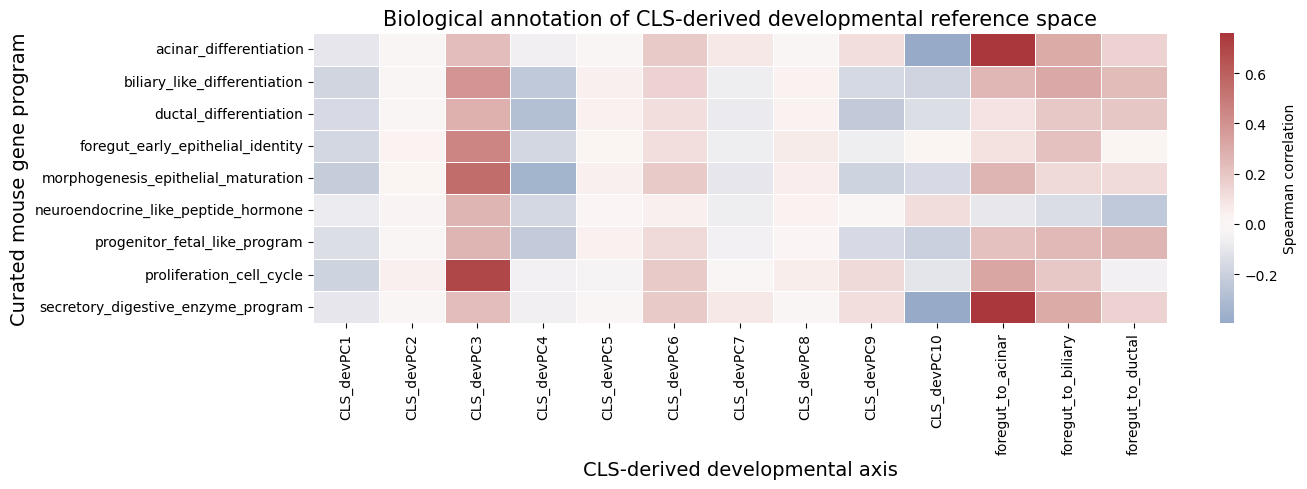

/home/jfpoyatos/Work/MNCN_24_25/A - plasticity - What's next/scripts/data/Mouse/annotation/figures/supp_fig_cls_developmental_axis_program_heatmap.pdf


In [52]:
plt.figure(figsize=(14, 5))

sns.heatmap(
    program_corr_matrix,
    cmap="vlag",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"}
)

plt.title("Biological annotation of CLS-derived developmental reference space",fontsize=15)
plt.xlabel("CLS-derived developmental axis",fontsize=14)
plt.ylabel("Curated mouse gene program",fontsize=14)
plt.tight_layout()

fig_path = os.path.join(
    OUTDIR,
    "figures",
    "supp_fig_cls_developmental_axis_program_heatmap.pdf"
)

plt.savefig(fig_path)
plt.show()

print(fig_path)

>compact summary

In [53]:
summary_rows = []

for axis_name, corr_df in axis_gene_tables.items():
    top_positive_genes = (
        corr_df.sort_values("correlation", ascending=False)
        .head(15)["gene"]
        .tolist()
    )

    top_negative_genes = (
        corr_df.sort_values("correlation", ascending=True)
        .head(15)["gene"]
        .tolist()
    )

    top_programs = (
        program_corr[program_corr["axis"] == axis_name]
        .sort_values("abs_spearman_r", ascending=False)
        .head(5)
    )

    summary_rows.append({
        "axis": axis_name,
        "axis_type": corr_df["axis_type"].iloc[0],
        "top_positive_genes": ", ".join(top_positive_genes),
        "top_negative_genes": ", ".join(top_negative_genes),
        "top_curated_programs": "; ".join(
            [
                f"{row.program}: r={row.spearman_r:.2f}"
                for row in top_programs.itertuples()
            ]
        ),
    })

axis_summary = pd.DataFrame(summary_rows)

axis_summary.to_csv(
    os.path.join(OUTDIR, "biological_axis_annotation_summary.csv"),
    index=False,
)

axis_summary

,axis,axis_type,top_positive_genes,top_negative_genes,top_curated_programs
0,CLS_devPC1,CLS_embedding_PC,"Gm29543, 4930426L09Rik, Muc2, Gm5784, 9930038B...","Tcf12, Rere, Ankrd17, Exoc4, Pard3, Fubp1, Fnd...",morphogenesis_epithelial_maturation: r=-0.22; ...
1,CLS_devPC2,CLS_embedding_PC,"Serpinh1, Ambp, Mxra7, Susd4, Grip1, Clspn, Gr...","Arhgef28, Galnt7, Ptprn2, Rhobtb1, Ghr, Cystm1...",proliferation_cell_cycle: r=0.04; foregut_earl...
2,CLS_devPC3,CLS_embedding_PC,"Hnrnpa2b1, Tcf12, Nedd4, Hnrnpu, Stag1, Exoc4,...","Neat1, Syt8, Fer1l4, Il18, Dmbt1, Eps8l3, Ern2...",proliferation_cell_cycle: r=0.70; morphogenesi...
3,CLS_devPC4,CLS_embedding_PC,"Galntl6, Sall4, Cldn6, Mdk, Nepn, Spon1, Zim1,...","Luc7l2, Atrnl1, Rbm39, Alcam, Kmt2c, Zcchc7, M...",morphogenesis_epithelial_maturation: r=-0.35; ...
4,CLS_devPC5,CLS_embedding_PC,"Rhobtb1, Rab27b, Arhgap24, Gmds, Sytl2, Slc9a4...","Top2a, Cenpe, Ncapg, Mki67, Knl1, Tpx2, Aspm, ...",morphogenesis_epithelial_maturation: r=0.05; b...
5,CLS_devPC6,CLS_embedding_PC,"Snd1, Stard13, Adk, Lrrc7, Sntb1, Pbx3, Slit3,...","Ache, Oasl2, Pgm5, Sp100, Trp63, Tnc, Sh3rf3, ...",proliferation_cell_cycle: r=0.19; morphogenesi...
6,CLS_devPC7,CLS_embedding_PC,"Slc38a3, Cpa1, Pnliprp1, Rbpjl, Gc, Slit3, Klb...","Atrnl1, Macf1, Lpp, Erbin, Patj, Chd6, Tcf4, M...",morphogenesis_epithelial_maturation: r=-0.10; ...
7,CLS_devPC8,CLS_embedding_PC,"Rora, Dapk1, Rbpms, Rbms3, Ppp1r9a, Grb10, Trp...","Ern2, Gmds, Slc9a4, Sytl2, Pde4d, Rhobtb1, Sid...",foregut_early_epithelial_identity: r=0.06; pro...
8,CLS_devPC9,CLS_embedding_PC,"Gpc6, Flrt2, Ptn, Peg3, Enox1, Prox1, Grb10, S...","Neat1, Myo1d, Gmds, Camk2d, Pdlim5, Far1, Rab2...",ductal_differentiation: r=-0.23; morphogenesis...
9,CLS_devPC10,CLS_embedding_PC,"Rora, Col4a2, Cdh4, Chst11, Col4a1, Boc, Grk5,...","Ghr, Mecom, Gata4, Arhgap24, Pik3c2g, Ptprn2, ...",secretory_digestive_enzyme_program: r=-0.39; a...


>### GSEA analysis 
(*not used at the end*)

MSigDB (Molecular Signatures Database) collections are curated sets of gene sets used for gene set enrichment analyses.\
The mouse collections are MSigDB gene‑set collections mapped or curated specifically for Mus musculus (mouse). 

Files at msigdb_mouse_gmt directory:
- wget -P  https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2025.1.Mm/m5.go.bp.v2025.1.Mm.symbols.gmt
- wget -P  https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2025.1.Mm/m2.cp.reactome.v2025.1.Mm.symbols.gmt
- wget -P  https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2025.1.Mm/mh.all.v2025.1.Mm.symbols.gmt

In [ ]:
# mouse (Mm) MSigDB C5 collection for Gene Ontology Biological Process (GO:BP) 
# specifically the M5 (MSigDB v5-style) GO BP gene sets mapped to mouse symbols, release v2025.1.
GMT_PATH = os.path.join(msigdb_dir,"m5.go.bp.v2025.1.Mm.symbols.gmt")

In [ ]:
def run_prerank_gsea_for_axis(
    ranked_df,
    axis_name,
    gmt_path,
    outdir,
    min_size=10,
    max_size=500,
    permutation_num=1000,
):
    """
    Run preranked GSEA for one developmental axis.
    Genes are ranked by correlation with the axis.
    """

    if gp is None:
        raise ImportError("gseapy is not installed. Install with: pip install gseapy")

    if gmt_path is None:
        raise ValueError("No GMT file supplied.")

    axis_outdir = os.path.join(
        OUTDIR,
        "gsea",
        axis_name.replace("/", "_")
    )

    os.makedirs(axis_outdir, exist_ok=True)

    ranking = (
        ranked_df[["gene", "correlation"]]
        .dropna()
        .sort_values("correlation", ascending=False)
    )

    pre_res = gp.prerank(
        rnk=ranking,
        gene_sets=gmt_path,
        outdir=axis_outdir,
        min_size=min_size,
        max_size=max_size,
        permutation_num=permutation_num,
        seed=7,
        verbose=False,
    )

    res = pre_res.res2d.copy()
    res["axis"] = axis_name

    res.to_csv(
        os.path.join(axis_outdir, "gsea_results.csv"),
        index=False,
    )

    return res

In [114]:
# .. this took ~1/2 hour to compute
# .. this took ~1/2 hour to compute

all_gsea_results = []

if GMT_PATH is not None:
    for axis_name, corr_df in axis_gene_tables.items():
        print(f"Running GSEA for {axis_name}")

        res = run_prerank_gsea_for_axis(
            ranked_df=corr_df,
            axis_name=axis_name,
            gmt_path=GMT_PATH,
            outdir=OUTDIR,
        )

        all_gsea_results.append(res)

    all_gsea_results = pd.concat(all_gsea_results, ignore_index=True)

    all_gsea_results.to_csv(
        os.path.join(OUTDIR, "all_axes_gsea_results.csv"),
        index=False,
    )

    display(all_gsea_results.head())
else:
    print("Skipping GSEA because GMT_PATH is None.")

2026-05-05 12:46:42,167 [WARNING] Duplicated values found in preranked stats: 1.05% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Running GSEA for CLS_PC1


2026-05-05 12:48:50,835 [WARNING] Duplicated values found in preranked stats: 1.05% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Running GSEA for CLS_PC2


2026-05-05 12:51:03,602 [WARNING] Duplicated values found in preranked stats: 1.05% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Running GSEA for CLS_PC3


... (17 outputs left out)

Running GSEA for foregut_to_acinar


2026-05-05 13:13:04,664 [WARNING] Duplicated values found in preranked stats: 1.05% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Running GSEA for foregut_to_biliary


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,axis
0,prerank,GOBP_POSITIVE_REGULATION_OF_HUMORAL_IMMUNE_RES...,0.673849,2.447566,0.0,0.0,0.0,15/15,32.68%,Il1b;Trem2;Ccr7;Mbl2;Tnf;Lta;Hpx;Gimap5;Acod1;...,CLS_PC1
1,prerank,GOBP_POSITIVE_REGULATION_OF_ANTIGEN_PROCESSING...,0.671201,2.148476,0.0,0.008741,0.005,11/11,32.93%,Trem2;Ccr7;Ccl19;Fam3d;Tap2;Pycard;Slc11a1;Ccl...,CLS_PC1
2,prerank,GOBP_DENDRITIC_CELL_ANTIGEN_PROCESSING_AND_PRE...,0.613096,2.116551,0.0,0.006993,0.006,13/13,38.74%,Ccr7;Ccl19;Cd68;Fcgr4;Slc11a1;Mpeg1;Ccl21a;Fgl...,CLS_PC1
3,prerank,GOBP_REGULATION_OF_CGMP_MEDIATED_SIGNALING,0.613056,2.076886,0.0,0.006993,0.008,12/12,38.74%,Nppb;Pde2a;Npr1;Nppc;Pde10a;Rundc3a;Adora2b;Kd...,CLS_PC1
4,prerank,GOBP_FEVER_GENERATION,0.583805,2.033989,0.0,0.008391,0.012,13/13,41.67%,Il1b;Il1a;Ccl5;Tnf;Tnfsf11;Ptges;Il1rn;Ptgs2;C...,CLS_PC1


In [115]:
if GMT_PATH is not None:
    # GSEApy column names sometimes vary by version.
    print(all_gsea_results.columns)

Index(['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val',
       'Tag %', 'Gene %', 'Lead_genes', 'axis'],
      dtype='object')


In [116]:
if GMT_PATH is not None:
    # Try to identify common columns.
    possible_fdr_cols = ["FDR q-val", "FDR", "fdr"]
    possible_term_cols = ["Term", "term", "Name"]

    fdr_col = next((c for c in possible_fdr_cols if c in all_gsea_results.columns), None)
    term_col = next((c for c in possible_term_cols if c in all_gsea_results.columns), None)

    if fdr_col is None or term_col is None:
        raise ValueError("Could not identify GSEA term or FDR columns. Inspect all_gsea_results.columns.")

    gsea_summary = (
        all_gsea_results
        .sort_values(["axis", fdr_col])
        .groupby("axis")
        .head(10)
        [["axis", term_col, fdr_col]]
    )

    gsea_summary.to_csv(
        os.path.join(OUTDIR, "top_gsea_terms_per_axis.csv"),
        index=False,
    )

    display(gsea_summary)

,axis,Term,FDR q-val
0,CLS_PC1,GOBP_POSITIVE_REGULATION_OF_HUMORAL_IMMUNE_RES...,0.0
5,CLS_PC1,GOBP_POSITIVE_REGULATION_OF_CYTOPLASMIC_TRANSL...,0.0
6,CLS_PC1,GOBP_MRNA_SPLICE_SITE_RECOGNITION,0.0
9,CLS_PC1,GOBP_CRD_MEDIATED_MRNA_STABILIZATION,0.001634
13,CLS_PC1,GOBP_PORE_COMPLEX_ASSEMBLY,0.00182
...,...,...,...
50694,foregut_to_ductal,GOBP_PROXIMAL_DISTAL_PATTERN_FORMATION,0.011105
50699,foregut_to_ductal,GOBP_POSITIVE_REGULATION_OF_ENDOTHELIAL_CELL_A...,0.01139
50697,foregut_to_ductal,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PE...,0.011404
50695,foregut_to_ductal,GOBP_T_CELL_APOPTOTIC_PROCESS,0.011422


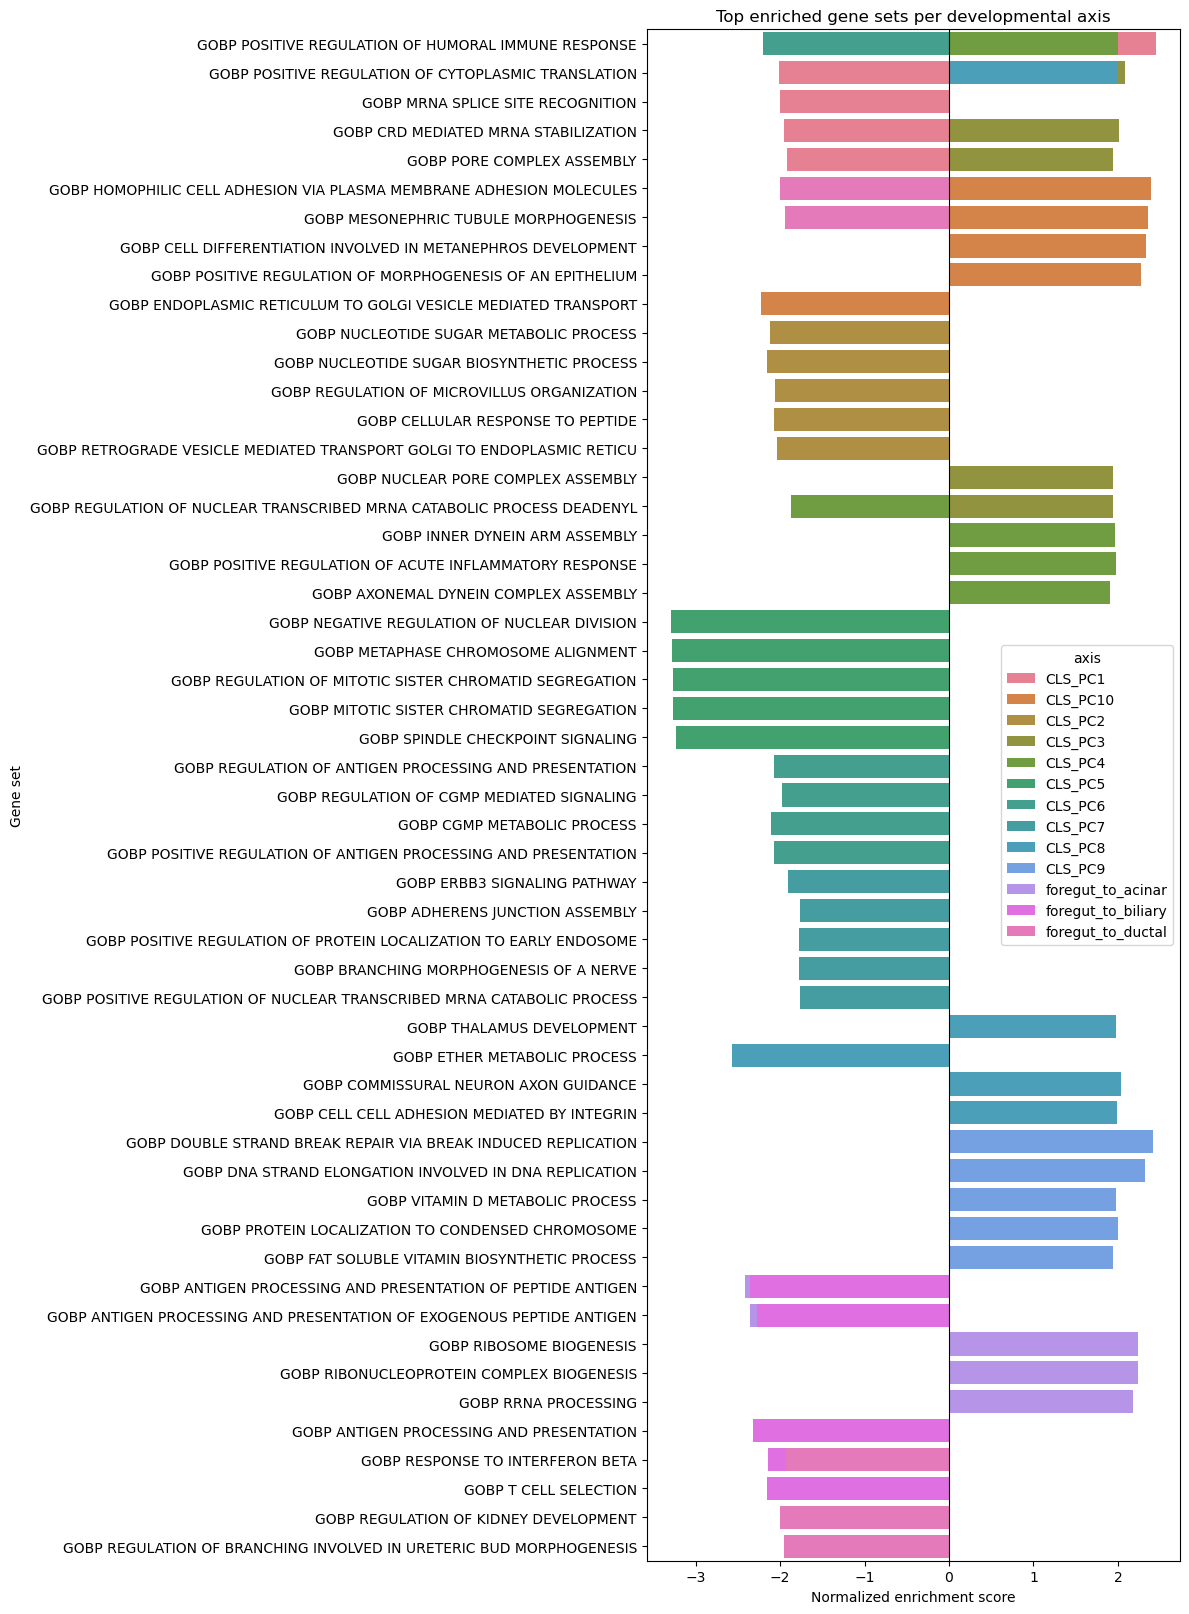

/home/jfpoyatos/Work/MNCN_24_25/A - plasticity - What's next/scripts/data/Mouse/annotation/figures/supp_fig_top_gsea_terms_per_axis.pdf


In [117]:
if GMT_PATH is not None and sns is not None:
    # Identify NES column.
    possible_nes_cols = ["NES", "nes"]
    nes_col = next((c for c in possible_nes_cols if c in all_gsea_results.columns), None)

    if nes_col is None:
        print("Could not identify NES column.")
    else:
        plot_df = (
            all_gsea_results
            .sort_values(["axis", fdr_col])
            .groupby("axis")
            .head(5)
            .copy()
        )

        # Keep labels short enough for plotting.
        plot_df["short_term"] = plot_df[term_col].str.replace("_", " ").str.slice(0, 70)

        plt.figure(figsize=(12, max(6, 0.25 * plot_df.shape[0])))

        sns.barplot(
            data=plot_df,
            x=nes_col,
            y="short_term",
            hue="axis",
            dodge=False
        )

        plt.axvline(0, color="black", linewidth=0.8)
        plt.xlabel("Normalized enrichment score")
        plt.ylabel("Gene set")
        plt.title("Top enriched gene sets per developmental axis")
        plt.tight_layout()

        fig_path = os.path.join(
            OUTDIR,
            "figures",
            "supp_fig_top_gsea_terms_per_axis.pdf"
        )

        plt.savefig(fig_path)
        plt.show()

        print(fig_path)

----

In [112]:
for axis_name in [
    "foregut_to_ductal",
    "foregut_to_acinar",
    "foregut_to_biliary",
]:
    adata.obs[axis_name + "_coord"] = axis_values[axis_name]

In [113]:
if "X_umap" in adata.obsm:
    sc.pl.umap(
        adata,
        color=[
            LINEAGE_COL,
            "foregut_to_ductal_coord",
            "foregut_to_acinar_coord",
            "foregut_to_biliary_coord",
        ],
        cmap="viridis",
        frameon=False,
        wspace=0.4,
    )
else:
    print("No UMAP found in adata.obsm['X_umap']. Skipping UMAP visualization.")

No UMAP found in adata.obsm['X_umap']. Skipping UMAP visualization.


----

### 2. Characterize the malignant residual component as cancer biology, not just “non-developmental variation”

The protocol should be the same as before in structure: axis scores per cell × gene expression per same cell
- **Previously**: developmental axis -> PC scores across developmental cells correlated with developmental expression matrix across developmental cells
- **Now**: cancer *residual* PC scores across cancer cells correlated with cancer expression matrix across cancer cells


**Residual axes**

In [48]:
# Center using DEV mean
# mu = X_dev.mean(axis=0)  # column-wise mean
Xc = X_can - mu

# .. cancer on developmental PCA
Xc_pca = pca.transform(Xc)

# Reconstruct cancer back 
can_recon = Xc_pca @ basis.T

# Orthogonal residual
Xc_residual = Xc - can_recon

# Center residuals
# substract the average residual vector across all cells
Xc_residual_centered = Xc_residual - Xc_residual.mean(axis=0) # axis 0: down to rows
print('Xc_residual_centered dims:',Xc_residual_centered.shape)

pca_res = PCA().fit(Xc_residual_centered)

print("Residual variance explained by first 10 PCs:",
      pca_res.explained_variance_ratio_[:10].sum())

print("Residual variance explained by first 30 PCs:",
      pca_res.explained_variance_ratio_[:30].sum())


Xc_residual_centered dims: (28131, 256)
Residual variance explained by first 10 PCs: 0.67201215
Residual variance explained by first 30 PCs: 0.8766998


In [45]:
# Inspect variance explained by CLS cancer residual PCA
# Cancer residual PCA object is available as 'pca_res'

if "PCA" in globals():
    var_df = pd.DataFrame({
        "component": [f"CLS_PC{i+1}" for i in range(len(pca_res.explained_variance_ratio_))],
        "explained_variance_ratio": pca_res.explained_variance_ratio_,
        "cumulative_variance": np.cumsum(pca_res.explained_variance_ratio_),
    })
    display(var_df.head(20))

    var_df.to_csv(os.path.join(OUTDIR, "cls_res_pca_explained_variance.csv"),index=False)
else:
    print("No object named `pca` found. Skipping explained variance table.")

,component,explained_variance_ratio,cumulative_variance
0,CLS_PC1,0.176626,0.176626
1,CLS_PC2,0.100545,0.277171
2,CLS_PC3,0.078343,0.355515
3,CLS_PC4,0.065693,0.421207
4,CLS_PC5,0.060113,0.481320
5,CLS_PC6,0.049161,0.530481
6,CLS_PC7,0.046950,0.577430
7,CLS_PC8,0.039730,0.617160
8,CLS_PC9,0.029390,0.646550
9,CLS_PC10,0.025462,0.672012


In [49]:
# Cancer metadata
# Paths (must match your previous save locations)
in_cancer = os.path.join(commonpathlocal,commonpath, "can/A_cancer_aln3.h5ad")
A_cancer_aln = sc.read_h5ad(in_cancer)

print(A_cancer_aln)
print("obs columns:", list(A_cancer_aln.obs.columns))
A_cancer_aln.var.head(6)

AnnData object with n_obs × n_vars = 28131 × 15376
    obs: 'batch', 'condition', 'cluster', 'epi_score', 'cancer_state', 'condition_collapsed'
    var: 'symbol_orig', 'symbol'
obs columns: ['batch', 'condition', 'cluster', 'epi_score', 'cancer_state', 'condition_collapsed']


,symbol_orig,symbol
ENSMUSG00000000001,GNAI3,Gnai3
ENSMUSG00000000028,CDC45,Cdc45
ENSMUSG00000000031,H19,H19
ENSMUSG00000000049,APOH,Apoh
ENSMUSG00000000056,NARF,Narf
ENSMUSG00000000058,CAV2,Cav2


In [107]:
STATE_COL

'cancer_state'

In [108]:
# Subset AnnData to match Xd_pca_sub
adata_can = A_cancer_aln.copy()

# Labels corresponding to Xd_pca_sub rows
labels_can = A_cancer_aln.obs["cancer_state"].astype(str).values
labels_can

array(['transitional', 'transitional', 'transitional', ..., 'ductal',
       'ductal', 'ductal'], dtype=object)

In [53]:
# Recall, this is computed above:
# cancer on developmental PCA --> Xc_pca = pca.transform(Xc)
# Reconstruct cancer back --> can_recon = Xc_pca @ basis.T
# Xc_residual = Xc - can_reconReconstructed 
# Xc_residual_centered = Xc_residual - Xc_residual.mean(axis=0) # axis 0: down to rows

# residual PC coordinates 
Xc_res_pca = PCA().fit_transform(Xc_residual_centered) # pca_res before
coords_canres = np.asarray(Xc_res_pca)
print("coords_can_res shape:", coords_canres.shape)
print("Number of dimensions available:", coords_canres.shape[1])

if coords_canres.shape[1] < max(N_PCS_TO_ANNOTATE, N_PCS_FOR_LINEAGE_DIRECTIONS):
    raise ValueError(
        f"Xd_pca_sub has only {coords_canres.shape[1]} dimensions, but requested "
        f"{max(N_PCS_TO_ANNOTATE, N_PCS_FOR_LINEAGE_DIRECTIONS)}."
    )

print("N_PCS_TO_ANNOTATE: ",N_PCS_TO_ANNOTATE)


coords_can_res shape: (28131, 256)
Number of dimensions available: 256
N_PCS_TO_ANNOTATE:  10


**Annotate residual cancer PCs by gene expression**

In [74]:
# Last check
assert adata_can.n_obs == coords_canres.shape[0], (f"Mismatch: adata_can has {adata_can.n_obs} cells, "f"coords_canres has {coords_canres.shape[0]} rows.")

In [56]:
# ..
axis_values_canres = {}
axis_gene_tables_canres = {}

os.makedirs(os.path.join(OUTDIR_c, "axis_gene_correlations"), exist_ok=True)
os.makedirs(os.path.join(OUTDIR_c, "top_genes"), exist_ok=True)

for pc_idx in range(N_PCS_TO_ANNOTATE):
    axis_name = f"ResCLS_PC{pc_idx + 1}"
    axis_coord = coords_canres[:, pc_idx]

    axis_values_canres[axis_name] = axis_coord

    corr_can_df = gene_axis_correlations(adata_can,axis_coord,layer=LAYER,method=CORR_METHOD)

    corr_can_df["axis"] = axis_name
    corr_can_df["axis_type"] = "CLS_residual_cancer_PC"

    axis_gene_tables_canres[axis_name] = corr_can_df

    corr_can_df.to_csv(os.path.join(OUTDIR_c,"axis_gene_correlations",f"{axis_name}_gene_correlations.csv",),index=False)
    corr_can_df.head(100).to_csv(os.path.join(OUTDIR_c,"top_genes",f"{axis_name}_top_100_genes.csv",),index=False)
    print(f"{axis_name}_gene_correlations.csv")
    print(f"{axis_name}_top_100_genes.csv")

print("")
print(f"Annotated ResCLS_PC1-ResCLS_PC{N_PCS_TO_ANNOTATE}")

ResCLS_PC1_gene_correlations.csv
ResCLS_PC1_top_100_genes.csv
ResCLS_PC2_gene_correlations.csv
ResCLS_PC2_top_100_genes.csv
ResCLS_PC3_gene_correlations.csv
ResCLS_PC3_top_100_genes.csv
ResCLS_PC4_gene_correlations.csv
ResCLS_PC4_top_100_genes.csv
ResCLS_PC5_gene_correlations.csv
ResCLS_PC5_top_100_genes.csv
ResCLS_PC6_gene_correlations.csv
ResCLS_PC6_top_100_genes.csv
ResCLS_PC7_gene_correlations.csv
ResCLS_PC7_top_100_genes.csv
ResCLS_PC8_gene_correlations.csv
ResCLS_PC8_top_100_genes.csv
ResCLS_PC9_gene_correlations.csv
ResCLS_PC9_top_100_genes.csv
ResCLS_PC10_gene_correlations.csv
ResCLS_PC10_top_100_genes.csv

Annotated ResCLS_PC1-ResCLS_PC10


**Cancer programs**

In [58]:
CANCER_PROGRAMS_MOUSE = {
    "emt_invasion": [
        "Vim", "Fn1", "Zeb1", "Zeb2", "Snai1", "Snai2", "Twist1",
        "Cdh2", "Itga5", "Itgav", "Itgb1", "Mmp2", "Mmp9", "Mmp14",
        "Col1a1", "Col1a2", "Col3a1", "Sparc", "Tnc", "Lox", "Postn"
    ],

    "epithelial_identity": [
        "Epcam", "Cdh1", "Krt8", "Krt18", "Krt19", "Krt7",
        "Cldn3", "Cldn4", "Cldn7", "Ocln", "Tjp1", "Muc1"
    ],

    "inflammatory_signaling": [
        "Nfkb1", "Nfkb2", "Rela", "Relb", "Tnf", "Tnfaip3",
        "Il1a", "Il1b", "Il6", "Cxcl1", "Cxcl2", "Cxcl10",
        "Ccl2", "Ccl5", "Ptgs2", "Socs3", "Icam1"
    ],

    "interferon_response": [
        "Stat1", "Stat2", "Irf1", "Irf7", "Irf9",
        "Isg15", "Ifit1", "Ifit2", "Ifit3", "Ifitm1", "Ifitm2", "Ifitm3",
        "Oas1a", "Oas1g", "Oas2", "Oas3", "Mx1", 
        "Rsad2", "Usp18", "Dhx58"
    ],

    "hypoxia": [
        "Hif1a", "Vegfa", "Slc2a1", "Ldha", "Pdk1",
        "Eno1", "Aldoa", "Bnip3", "Ndrg1", "Adm", "Car9",
        "Serpine1", "Ero1a", "Ankrd37"
    ],

    "oxidative_stress": [
        "Nfe2l2", "Keap1", "Hmox1", "Nqo1", "Gclc", "Gclm",
        "Gsr", "Gpx2", "Gpx4", "Prdx1", "Txn1",
        "Txnrd1", "Srxn1", "Sqstm1", "Ftl1", "Fth1"
    ],

    "unfolded_protein_response": [
        "Hspa5", "Hsp90b1", "Ddit3", "Atf3", "Atf4", "Atf6",
        "Xbp1", "Ern1", "Eif2ak3", "Pdia3", "Pdia4", "Pdia6",
        "Dnajb9", "Herpud1", "Derl3", "Manf", "Creld2"
    ],

    "kras_mapk_signaling": [
        "Dusp4", "Dusp5", "Dusp6", "Etv1", "Etv4", "Etv5",
        "Spry1", "Spry2", "Spry4", "Fos", "Fosl1", "Jun", "Junb",
        "Egr1", "Egr2", "Ets1", "Myc", "Mapk1", "Mapk3"
    ],

    "myc_targets": [
        "Myc", "Max", "Mxd1", "Npm1", "Ncl", "Odc1", "Cad",
        "Nme1", "Nme2", "Hspd1", "Hspe1", "Tfrc", "Slc2a1",
        "Phb", "Pa2g4", "Hnrnpa1", "Hnrnpa2b1", "Eif4a1"
    ],

    "p53_pathway": [
        "Trp53", "Cdkn1a", "Mdm2", "Bax", "Bbc3", "Pmaip1",
        "Gadd45a", "Gadd45g", "Sesn1", "Sesn2", "Ddb2",
        "Phlda3", "Zmat3", "Rrm2b", "Ccng1"
    ],

    "cell_cycle": [
        "Mki67", "Top2a", "Pcna", "Mcm2", "Mcm3", "Mcm4",
        "Mcm5", "Mcm6", "Mcm7", "Cdk1", "Ccnb1", "Ccnb2",
        "Cenpa", "Cenpe", "Cenpf", "Tpx2", "Bub1b", "Ube2c",
        "Aspm", "Nusap1", "Kif11", "Kif20b"
    ],

    "dna_damage_repair": [
        "Brca1", "Brca2", "Rad51", "Rad51ap1", "Msh2", "Msh6",
        "Pms2", "Pcna", "Rpa1", "Rpa2", "Chek1", "Chek2",
        "Atm", "Atr", "Fanca", "Fancc", "Xrcc5", "Xrcc6"
    ],

    "glycolysis_metabolic_rewiring": [
        "Slc2a1", "Hk1", "Hk2", "Pfkl", "Pfkp", "Aldoa",
        "Gapdh", "Pgam1", "Eno1", "Pkm", "Ldha",
        "Pdk1", "Slc16a3"
    ],

    "oxidative_phosphorylation_mitochondrial": [
        "Ndufa2", "Ndufa4", "Ndufb3", "Ndufb5",
        "Sdha", "Sdhb", "Uqcrc1", "Uqcrc2", "Cyc1",
        "Cox4i1", "Cox5a", "Atp5f1a", "Atp5f1b", "Atp5mc1"
    ],

    "ecm_remodeling_invasion": [
        "Fn1", "Col1a1", "Col1a2", "Col3a1", "Col4a1", "Col4a2",
        "Col5a1", "Col5a2", "Sparc", "Tnc", "Postn", "Lox",
        "Loxl2", "Mmp2", "Mmp9", "Mmp14", "Itga5", "Itgav",
        "Itgb1", "Vcan", "Thbs1"
    ],

    "antigen_presentation_mhc_i": [
        "B2m", "H2-K1", "H2-D1", "Tap1", "Tap2",
        "Tapbp", "Psmb8", "Psmb9", "Psmb10", "Nlrc5"
    ],

    "antigen_presentation_mhc_ii": [
        "H2-Aa", "H2-Ab1", "H2-Eb1", "Cd74", "Ciita",
        "H2-DMa", "H2-DMb1", "H2-Ob"
    ],

    "stemness_progenitor_like": [
        "Sox9", "Prom1", "Aldh1a1", "Aldh1a3", "Lgr5",
        "Krt19", "Epcam", "Tacstd2", "Muc1", "Nes",
        "Vim", "Lgals1", "S100a10"
    ],

    "therapy_resistance_stress_tolerance": [
        "Aldh1a1", "Aldh1a3", "Abcb1a", "Abcb1b", "Abcc1",
        "Abcc3", "Abcg2", "Bcl2", "Bcl2l1", "Mcl1",
        "Hspa1a", "Hspa1b", "Hspa5", "Hmox1", "Nqo1",
        "Sod2", "Gpx2", "Lgals1", "Tgfb1", "Vim"
    ],

    "tgfb_signaling": [
        "Tgfb1", "Tgfb2", "Tgfbr1", "Tgfbr2", "Smad2", "Smad3",
        "Smad4", "Serpine1", "Id1", "Id2",
        "Id3", "Skil", "Snai1", "Snai2"
    ],

    "apoptosis": [
        "Bax", "Bak1", "Bbc3", "Pmaip1", "Casp3", "Casp7",
        "Casp8", "Casp9", "Apaf1", "Bid", "Bad", "Bcl2",
        "Bcl2l1", "Mcl1"
    ],

    "senescence_sasp": [
        "Cdkn1a", "Cdkn2a", "Trp53", "Il6", "Cxcl1", "Cxcl2",
        "Ccl2", "Serpine1", "Mmp3", "Mmp9", "Igfbp3",
        "Igfbp5", "Gadd45a"
    ],
    
    "ap1_immediate_early_response": [
       "Fos", "Fosb", "Fosl1", "Fosl2",
        "Jun", "Junb", "Jund",
        "Atf3", "Egr1", "Egr2",
        "Dusp1", "Dusp5", "Dusp6",
        "Ier2", "Csrnp1", "Zfp36",
        "Btg2", "Ccn1", "Klf6"
    ]
}

##### *reusing some functions above*
- get_expression_matrix
- report_program_marker_coverage
- gene_axis_correlations
- score_programs
- correlate_program_scores

But, a safer version of the marker coverage and program scoring code.

In [59]:
def report_program_marker_coverage(adata, programs, gene_symbol_col="symbol"):
    rows = []

    if gene_symbol_col is not None and gene_symbol_col in adata.var.columns:
        gene_symbols = adata.var[gene_symbol_col].astype(str).values
    else:
        gene_symbols = adata.var_names.astype(str).values

    var_names = set(gene_symbols)

    for program, genes in programs.items():
        present = [g for g in genes if g in var_names]
        missing = [g for g in genes if g not in var_names]

        rows.append({
            "program": program,
            "n_total": len(genes),
            "n_present": len(present),
            "fraction_present": len(present) / len(genes),
            "present_genes": ", ".join(present),
            "missing_genes": ", ".join(missing),
        })

    return pd.DataFrame(rows).sort_values("fraction_present")

In [60]:
# Use min_genes=3 or min_genes=5 for cancer programs in this case
def score_programs(adata,programs,layer=None,min_genes=3,gene_symbol_col="symbol"):
    X = get_expression_matrix(adata, layer=layer)

    if gene_symbol_col is not None and gene_symbol_col in adata.var.columns:
        genes = adata.var[gene_symbol_col].astype(str).values
    else:
        genes = adata.var_names.astype(str).values

    # Warn about duplicates because duplicate gene symbols can silently distort scoring.
    duplicated = pd.Series(genes).duplicated().sum()
    if duplicated > 0:
        print(f"Warning: {duplicated} duplicated gene symbols detected. Using first occurrence only.")

    gene_to_idx = {}
    for idx, gene in enumerate(genes):
        if gene not in gene_to_idx:
            gene_to_idx[gene] = idx

    scores = {}

    for program, gene_list in programs.items():
        present = [g for g in gene_list if g in gene_to_idx]

        if len(present) < min_genes:
            print(f"Skipping {program}: only {len(present)} marker(s) found.")
            continue

        idx = [gene_to_idx[g] for g in present]

        if sp.issparse(X):
            score = np.asarray(X[:, idx].mean(axis=1)).ravel()
        else:
            score = X[:, idx].mean(axis=1)

        scores[program] = score

    return pd.DataFrame(scores, index=adata.obs_names)

**Cancer program marker coverage** (I used this, as before, to identify which genes in the initiall call of the programs were not present)

In [61]:
marker_coverage_can = report_program_marker_coverage(adata_can,CANCER_PROGRAMS_MOUSE,gene_symbol_col="symbol")
marker_coverage_can.to_csv(os.path.join(OUTDIR_c, "cancer_program_marker_coverage.csv"),index=False)

marker_coverage_can

,program,n_total,n_present,fraction_present,present_genes,missing_genes
0,emt_invasion,21,21,1.0,"Vim, Fn1, Zeb1, Zeb2, Snai1, Snai2, Twist1, Cd...",
1,epithelial_identity,12,12,1.0,"Epcam, Cdh1, Krt8, Krt18, Krt19, Krt7, Cldn3, ...",
2,inflammatory_signaling,17,17,1.0,"Nfkb1, Nfkb2, Rela, Relb, Tnf, Tnfaip3, Il1a, ...",
3,interferon_response,20,20,1.0,"Stat1, Stat2, Irf1, Irf7, Irf9, Isg15, Ifit1, ...",
4,hypoxia,14,14,1.0,"Hif1a, Vegfa, Slc2a1, Ldha, Pdk1, Eno1, Aldoa,...",
5,oxidative_stress,16,16,1.0,"Nfe2l2, Keap1, Hmox1, Nqo1, Gclc, Gclm, Gsr, G...",
6,unfolded_protein_response,17,17,1.0,"Hspa5, Hsp90b1, Ddit3, Atf3, Atf4, Atf6, Xbp1,...",
7,kras_mapk_signaling,19,19,1.0,"Dusp4, Dusp5, Dusp6, Etv1, Etv4, Etv5, Spry1, ...",
8,myc_targets,18,18,1.0,"Myc, Max, Mxd1, Npm1, Ncl, Odc1, Cad, Nme1, Nm...",
9,p53_pathway,15,15,1.0,"Trp53, Cdkn1a, Mdm2, Bax, Bbc3, Pmaip1, Gadd45...",


In [62]:
# just in case; not required given the table above
usable_programs = marker_coverage_can.loc[
    (marker_coverage_can["n_present"] >= 5) &
    (marker_coverage_can["fraction_present"] >= 0.4),
    "program"
].tolist()

CANCER_PROGRAMS_MOUSE_USABLE = {
    k: v for k, v in CANCER_PROGRAMS_MOUSE.items()
    if k in usable_programs
}

print(f"Using {len(CANCER_PROGRAMS_MOUSE_USABLE)} cancer programs.")

Using 23 cancer programs.


**Score cancer programs per cancer cell**

In [63]:
cancer_program_scores = score_programs(adata_can,CANCER_PROGRAMS_MOUSE_USABLE,layer=LAYER,min_genes=5,gene_symbol_col="symbol")
cancer_program_scores.to_csv(os.path.join(OUTDIR_c, "curated_cancer_program_scores.csv"))

print("cancer_program_scores dimensions:", cancer_program_scores.shape)
cancer_program_scores.head()

cancer_program_scores dimensions: (28131, 23)


,emt_invasion,epithelial_identity,inflammatory_signaling,interferon_response,hypoxia,oxidative_stress,unfolded_protein_response,kras_mapk_signaling,myc_targets,p53_pathway,...,oxidative_phosphorylation_mitochondrial,ecm_remodeling_invasion,antigen_presentation_mhc_i,antigen_presentation_mhc_ii,stemness_progenitor_like,therapy_resistance_stress_tolerance,tgfb_signaling,apoptosis,senescence_sasp,ap1_immediate_early_response
120703424252788_DACD394_Kate_plus,0.285714,22.500000,0.294118,1.10,2.142857,13.2500,5.882354,4.000000,3.388889,1.000000,...,10.071429,0.333333,3.3,0.125,13.384616,4.350000,0.785714,0.928572,0.230769,7.368422
120703436605797_DACD394_Kate_plus,1.857143,33.250004,0.117647,1.60,2.285715,13.8125,3.117647,5.000000,3.888889,3.200000,...,8.214286,2.142857,3.5,0.000,13.153847,3.350000,0.571429,2.500000,1.384615,12.157894
120703436909853_DACD394_Kate_plus,4.571429,31.500000,3.058823,1.45,3.000000,11.3750,1.823529,3.578947,2.333333,4.666667,...,5.857143,4.476191,1.8,0.000,15.615385,4.850000,1.500000,1.428571,8.153847,8.578947
120703454952236_DACD394_Kate_plus,0.857143,68.416672,0.470588,2.05,7.285714,28.7500,5.764706,7.368421,12.388889,5.266667,...,20.428574,1.285714,5.6,0.000,26.846153,6.050000,2.071429,3.500000,3.615385,19.631578
120726896892262_DACD394_Kate_plus,2.190476,9.333333,1.705882,0.35,2.714286,18.8750,2.294118,2.842105,8.500000,1.200000,...,11.285715,1.523810,1.7,0.000,15.769231,8.950001,1.000000,2.071429,2.461539,3.789474


**Correlate residual PCs with cancer programs**\
This is the cancer equivalent of the *developmental* heatmap matrix.

In [64]:
cancer_program_corr = correlate_program_scores(axis_values_canres,cancer_program_scores)
cancer_program_corr.to_csv(os.path.join(OUTDIR_c, "residual_axis_cancer_program_correlations.csv"),index=False)

pivot_df = cancer_program_corr.pivot(index="program",columns="axis",values="spearman_r")
cols_sorted = sorted(
    pivot_df.columns,
    key=lambda x: int(re.search(r'\d+', x).group())
)
cancer_program_corr_matrix = pivot_df[cols_sorted]
cancer_program_corr_matrix.to_csv(os.path.join(OUTDIR_c, "residual_axis_cancer_program_correlation_matrix.csv"))

cancer_program_corr_matrix

axis,ResCLS_PC1,ResCLS_PC2,ResCLS_PC3,ResCLS_PC4,ResCLS_PC5,ResCLS_PC6,ResCLS_PC7,ResCLS_PC8,ResCLS_PC9,ResCLS_PC10
program,,,,,,,,,,
antigen_presentation_mhc_i,-0.503833,-0.007758,0.065222,-0.134938,-0.193313,-0.156504,-0.162258,-0.052218,-0.084584,0.155098
antigen_presentation_mhc_ii,-0.189236,-0.133171,0.017428,0.083584,-0.149189,-0.036613,-0.035382,0.079032,-0.062888,-0.019228
ap1_immediate_early_response,-0.705218,-0.011796,0.220015,0.301443,-0.171200,-0.251801,0.080638,-0.204511,-0.152408,0.013239
apoptosis,-0.648699,0.273271,0.170491,-0.210504,-0.098716,-0.220986,0.036839,-0.166004,-0.090425,0.107368
cell_cycle,-0.449408,0.226353,0.068820,-0.291075,0.071840,-0.137812,0.147652,-0.203775,-0.139975,-0.028529
dna_damage_repair,-0.497565,0.152853,0.136297,-0.223998,0.012917,-0.145046,0.084849,-0.199061,-0.155834,-0.001199
ecm_remodeling_invasion,-0.556924,0.479040,-0.076264,-0.175998,-0.030867,-0.117263,-0.059286,-0.177623,0.034354,-0.006585
emt_invasion,-0.509878,0.502669,-0.167531,-0.190884,-0.013896,-0.015280,0.024566,-0.250672,0.039730,0.031146
epithelial_identity,-0.688536,0.285098,0.249770,-0.250514,-0.050586,-0.266708,-0.013285,-0.065252,0.044042,0.176048


Heatmap matrix.

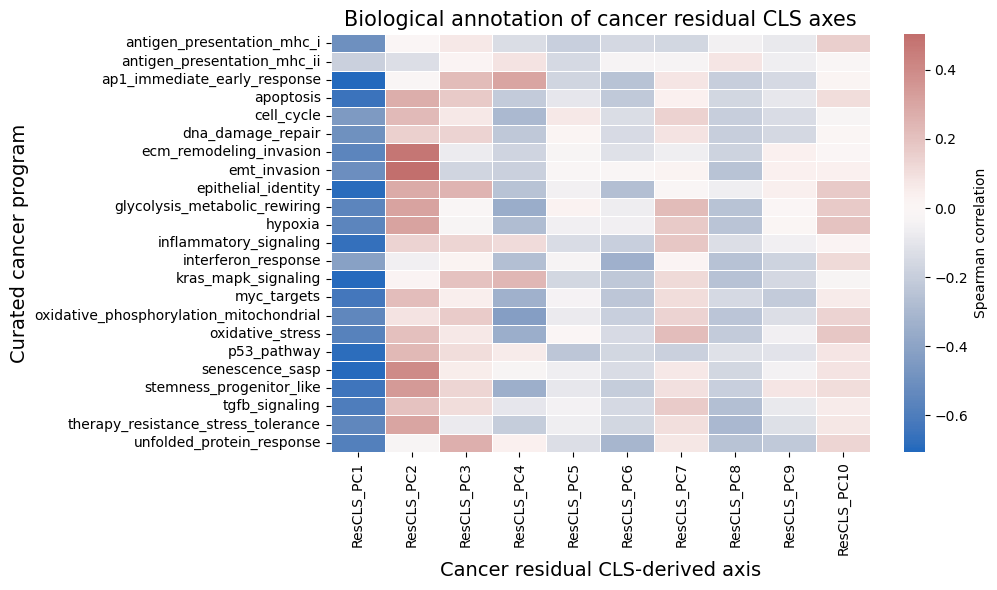

/home/jfpoyatos/Work/MNCN_24_25/A - plasticity - What's next/scripts/data/Mouse/annotation_malignant_residual_axes/figures/supp_fig_cancer_residual_axis_program_heatmap.pdf


In [65]:
plt.figure(figsize=(10.25, min(6, 0.35 * cancer_program_corr_matrix.shape[0])))

sns.heatmap(
    cancer_program_corr_matrix,
    cmap="vlag",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"},
)

plt.title("Biological annotation of cancer residual CLS axes",fontsize=15)
plt.xlabel("Cancer residual CLS-derived axis",fontsize=14)
plt.ylabel("Curated cancer program",fontsize=14)
plt.tight_layout()

fig_path = os.path.join(OUTDIR_c,"figures","supp_fig_cancer_residual_axis_program_heatmap.pdf")
os.makedirs(os.path.dirname(fig_path), exist_ok=True)

plt.savefig(fig_path)
plt.show()

print(fig_path)

**Summary Table**

In [66]:
summary_rows_canres = []

for axis_name, corr_df in axis_gene_tables_canres.items():
    top_positive_genes = (
        corr_df.sort_values("correlation", ascending=False)
        .head(15)["gene"]
        .tolist()
    )

    top_negative_genes = (
        corr_df.sort_values("correlation", ascending=True)
        .head(15)["gene"]
        .tolist()
    )

    top_programs = (
        cancer_program_corr[cancer_program_corr["axis"] == axis_name]
        .sort_values("abs_spearman_r", ascending=False)
        .head(7)
    )

    summary_rows_canres.append({
        "axis": axis_name,
        "axis_type": corr_df["axis_type"].iloc[0],
        "top_positive_genes": ", ".join(top_positive_genes),
        "top_negative_genes": ", ".join(top_negative_genes),
        "top_curated_cancer_programs": "; ".join(
            [
                f"{row.program}: r={row.spearman_r:.2f}"
                for row in top_programs.itertuples()
            ]
        ),
    })

cancer_axis_summary = pd.DataFrame(summary_rows_canres)

cancer_axis_summary.to_csv(os.path.join(OUTDIR_c, "cancer_residual_axis_annotation_summary.csv"),index=False)

cancer_axis_summary

,axis,axis_type,top_positive_genes,top_negative_genes,top_curated_cancer_programs
0,ResCLS_PC1,CLS_residual_cancer_PC,"Zg16, Rnase1, Cela1, Pnlip, Ctrl, Pla2g1b, Try...","Eef1a1, Ddx5, Ubb, Eef2, Morf4l1, Eif1, H3f3b,...",ap1_immediate_early_response: r=-0.71; kras_ma...
1,ResCLS_PC2,CLS_residual_cancer_PC,"Tpm1, Rtn4, Tpm4, Pdlim7, Sdc1, Antxr2, Anxa5,...","Dmbt1, Elapor1, Chchd10, Tmem45a, C4b, Tcea3, ...",emt_invasion: r=0.50; ecm_remodeling_invasion:...
2,ResCLS_PC3,CLS_residual_cancer_PC,"Kcnk1, Tmprss4, Atp1b1, Rab25, Prom1, Epcam, C...","Tmem97, Gamt, Try5, Pnliprp1, Try10, Reg3b, Re...",unfolded_protein_response: r=0.26; epithelial_...
3,ResCLS_PC4,CLS_residual_cancer_PC,"Jun, Klf6, Dusp1, Ccn1, Btg2, Fosb, Jund, Junb...","Atp5f1e, Atp5mf, Cox5a, Atp5mj, Uqcr11, Atp5me...",oxidative_phosphorylation_mitochondrial: r=-0....
4,ResCLS_PC5,CLS_residual_cancer_PC,"S100a14, Bri3, Ift172, 2310039H08Rik, Chmp6, 4...","Cftr, Tmem45a, Ctse, Tmem205, St8sia3, Clu, Dm...",p53_pathway: r=-0.23; antigen_presentation_mhc...
5,ResCLS_PC6,CLS_residual_cancer_PC,"Aplp1, Fam183b, Hmgn3, Scg5, Rab3b, Hepacam2, ...","Ctrb1, Pnliprp1, Reg1, Prss2, Cpa1, Reg2, Igf1...",interferon_response: r=-0.34; unfolded_protein...
6,ResCLS_PC7,CLS_residual_cancer_PC,"Npc2, Tpi1, Fam162a, Tpt1, Gapdh, Uba52rt, Ptg...","Enho, Atosa, Slc4a11, Mgmt, Crlf1, Sema7a, Fn1...",glycolysis_metabolic_rewiring: r=0.22; oxidati...
7,ResCLS_PC8,CLS_residual_cancer_PC,"Cldn4, Stbd1, Cldn3, Pamr1, Pnlip, Hsd17b13, P...","Fkbp2, Dad1, Ostc, Ssr2, Tmem258, Sec61b, Lsm6...",therapy_resistance_stress_tolerance: r=-0.30; ...
8,ResCLS_PC9,CLS_residual_cancer_PC,"Krt19, Ctse, Cwh43, Phgr1, AA467197, Mal, Cide...","Mrfap1, Hnrnpa1, Hmgn2, Ptma, Idh2, Prmt1, Cdk...",unfolded_protein_response: r=-0.22; myc_target...
9,ResCLS_PC10,CLS_residual_cancer_PC,"Cldn18, Krt20, Aldoa, Glul, Cystm1, Slc26a2, S...","Stmn1, Lsm5, Cenpw, Hmgb2, Mad2l1, Ranbp1, Hel...",hypoxia: r=0.20; oxidative_stress: r=0.18; epi...


----

### 3. Label malignant state positions with marker genes and programs

Recall objects required now:

- Cancer expression AnnData -->  adata_can
- Labels --> labels_can (transitional, ...)
- Cancer developmental coordinates, i.e.,, cancer projected into developmental PCA space --> Xc_pca
- Cancer residual PCA coordinates --> coords_canres
- Cancer program scores on cancer cells --> cancer_program_scores

- Developmental program scores on cancer cells; Optional but useful; compute using **PROGRAMS_MOUSE on adata_can** --> I compute this below (**dev_program_scores_can**)

- Residual PC axis values - > axis_values_canres??

In [67]:
STATE_COL = "cancer_state"  # replace with your actual column

N_DEV_PCS_FOR_STATE = 10
N_RES_PCS_FOR_STATE = 10

GENE_SYMBOL_COL = "symbol"
LAYER = None  # ideally normalized/log expression layer if available

In [68]:
# Basic checks
assert adata_can.n_obs == Xc_pca.shape[0]
assert adata_can.n_obs == coords_canres.shape[0]
assert adata_can.n_obs == cancer_program_scores.shape[0]

if STATE_COL not in adata_can.obs.columns:
    raise ValueError(f"{STATE_COL} not found in adata_can.obs")

states = adata_can.obs[STATE_COL].astype(str).values
print(pd.Series(states).value_counts())

transitional        13650
malignant_ductal     8855
ductal               5626
Name: count, dtype: int64


You need the lineage (*developmental centroids*)  and unit vectors from the developmental reference space.\
I compute them again 

In [70]:
def fit_lineage_direction(coords, labels, start_label, end_label, n_dims=75):
    labels = np.asarray(labels).astype(str)
    X = np.asarray(coords)[:, :n_dims]

    start_mask = labels == str(start_label)
    end_mask = labels == str(end_label)

    if start_mask.sum() == 0:
        raise ValueError(f"No cells found for start label: {start_label}")
    if end_mask.sum() == 0:
        raise ValueError(f"No cells found for end label: {end_label}")

    start_centroid = X[start_mask].mean(axis=0)
    end_centroid = X[end_mask].mean(axis=0)

    direction = end_centroid - start_centroid
    norm = np.linalg.norm(direction)

    if norm == 0:
        raise ValueError(f"Zero-length direction from {start_label} to {end_label}")

    unit_direction = direction / norm

    return {"start_label": start_label,"end_label": end_label,"n_dims": n_dims,"start_centroid": start_centroid,
            "end_centroid": end_centroid,"unit_direction": unit_direction}


def project_onto_lineage_direction(coords, direction_object):
    n_dims = direction_object["n_dims"]
    X = np.asarray(coords)[:, :n_dims]

    start_centroid = direction_object["start_centroid"]
    unit_direction = direction_object["unit_direction"]

    projection = (X - start_centroid) @ unit_direction
    return projection

In [71]:
# Recall - coords_dev = np.asarray(Xd_pca_sub)
print('coords_dev.shape', coords_dev.shape)
print('labels_dev:', labels_dev.shape)

coords_dev.shape (13437, 75)
labels_dev: (13437,)


Fit on developmental cells

In [72]:
N_PCS_FOR_LINEAGE_DIRECTIONS = 75

lineage_direction_objects = {}

lineage_specs = [
    ("foregut_to_ductal", "foregut", "ductal"),
    ("foregut_to_acinar", "foregut", "acinar"),
    ("foregut_to_biliary", "foregut", "biliary"),
]

for axis_name, start_label, end_label in lineage_specs:
    lineage_direction_objects[axis_name] = fit_lineage_direction(
        coords=coords_dev,
        labels=labels_dev,
        start_label=start_label,
        end_label=end_label,
        n_dims=N_PCS_FOR_LINEAGE_DIRECTIONS,
    )

print('lineage_direction_objects keys: ',lineage_direction_objects.keys())

lineage_direction_objects keys:  dict_keys(['foregut_to_ductal', 'foregut_to_acinar', 'foregut_to_biliary'])


**Project cancer cells on these developmental lineage axis**

In [75]:
for axis_name, direction_object in lineage_direction_objects.items():
    print('axis_name:', axis_name)
    print('direction_object:', direction_object.keys())
    print('')
    adata_can.obs[axis_name] = project_onto_lineage_direction(
        coords = Xc_pca,
        direction_object = direction_object,
    )

axis_name: foregut_to_ductal
direction_object: dict_keys(['start_label', 'end_label', 'n_dims', 'start_centroid', 'end_centroid', 'unit_direction'])

axis_name: foregut_to_acinar
direction_object: dict_keys(['start_label', 'end_label', 'n_dims', 'start_centroid', 'end_centroid', 'unit_direction'])

axis_name: foregut_to_biliary
direction_object: dict_keys(['start_label', 'end_label', 'n_dims', 'start_centroid', 'end_centroid', 'unit_direction'])



In [112]:
adata_can.obs

,batch,condition,cluster,epi_score,cancer_state,condition_collapsed,foregut_to_ductal,foregut_to_acinar,foregut_to_biliary
120703424252788_DACD394_Kate_plus,DACD394_Kate_plus,K1,0,19.874283,transitional,K1,5.906370,4.495972,4.916130
120703436605797_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,36.073220,transitional,K1,2.928420,3.271755,3.995218
120703436909853_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,34.452284,transitional,K1,3.222239,3.397321,3.791447
120703454952236_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,26.712270,transitional,K1,3.469100,4.116844,4.268833
120726896892262_DACD394_Kate_plus,DACD394_Kate_plus,K1,5,5.158195,transitional,K1,4.797621,4.533161,3.929073
...,...,...,...,...,...,...,...,...,...
241106402626286_DACD550_kate_plus,DACD550_kate_plus,N1,2,-4.427245,ductal,N,4.733507,5.721574,3.400442
241114562127587_DACD550_kate_plus,DACD550_kate_plus,N1,2,-5.558278,ductal,N,4.285614,5.420589,3.519394
241114576730845_DACD550_kate_plus,DACD550_kate_plus,N1,9,0.692000,ductal,N,1.367384,4.814298,3.655662
241114607893403_DACD550_kate_plus,DACD550_kate_plus,N1,2,-3.752480,ductal,N,4.095509,5.304900,3.186053


**Compute developmental program scores in cancer cells**\
You already computed cancer programs. Now score the developmental programs in cancer cells too.

This lets you ask whether a cancer state is ductal-like, acinar-like, biliary-like, proliferative, etc.

In [76]:
dev_program_scores_can = score_programs(adata_can,PROGRAMS_MOUSE,layer=LAYER,min_genes=3)
dev_program_scores_can.to_csv(os.path.join(OUTDIR_c, "cancer_cells_developmental_program_scores.csv"))

dev_program_scores_can.head()

,foregut_early_epithelial_identity,ductal_differentiation,acinar_differentiation,biliary_like_differentiation,proliferation_cell_cycle,morphogenesis_epithelial_maturation,secretory_digestive_enzyme_program,progenitor_fetal_like_program,neuroendocrine_like_peptide_hormone
120703424252788_DACD394_Kate_plus,20.333332,9.900001,29.769232,77.249992,0.000000,23.090910,8.000000,81.800003,0.090909
120703436605797_DACD394_Kate_plus,30.333332,13.500000,6.384615,15.749999,0.000000,33.454548,5.727273,6.000000,0.045455
120703436909853_DACD394_Kate_plus,28.666666,12.000001,7.538462,15.666667,0.071429,28.636366,7.181818,11.700001,0.000000
120703454952236_DACD394_Kate_plus,69.000000,24.699999,23.384617,25.666666,0.285714,71.454552,15.454546,15.500000,0.181818
120726896892262_DACD394_Kate_plus,9.222222,3.300000,9.692308,4.000000,1.214286,8.636363,8.181819,20.000000,0.090909


>**State-level averages for** developmental **coordinates.**
This summarizes where each cancer state sits in developmental space.

In [77]:
# Developmental PCA coordinates for cancer cells
for i in range(N_DEV_PCS_FOR_STATE):
    adata_can.obs[f"DevCLS_PC{i + 1}"] = Xc_pca[:, i]

# Residual cancer PCA coordinates
for i in range(N_RES_PCS_FOR_STATE):
    adata_can.obs[f"ResCLS_PC{i + 1}"] = coords_canres[:, i]

In [78]:
adata_can.obs

,batch,condition,cluster,epi_score,cancer_state,condition_collapsed,foregut_to_ductal,foregut_to_acinar,foregut_to_biliary,DevCLS_PC1,...,ResCLS_PC1,ResCLS_PC2,ResCLS_PC3,ResCLS_PC4,ResCLS_PC5,ResCLS_PC6,ResCLS_PC7,ResCLS_PC8,ResCLS_PC9,ResCLS_PC10
120703424252788_DACD394_Kate_plus,DACD394_Kate_plus,K1,0,19.874283,transitional,K1,5.906370,4.495972,4.916130,-1.082340,...,-1.946667,-2.510925,1.547584,-3.809390,-4.268847,0.883398,-1.234779,-0.999136,1.118366,0.020917
120703436605797_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,36.073220,transitional,K1,2.928420,3.271755,3.995218,-0.500085,...,-3.887090,3.349124,0.199115,-0.937792,-2.372127,-0.573969,-3.130004,1.245941,0.646739,-0.220810
120703436909853_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,34.452284,transitional,K1,3.222239,3.397321,3.791447,0.253304,...,-2.404723,5.657869,1.295832,2.410315,-0.302587,-0.430787,-4.155398,-0.692241,2.322344,2.275775
120703454952236_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,26.712270,transitional,K1,3.469100,4.116844,4.268833,-1.016040,...,-3.818455,2.073062,1.234276,-3.054271,-4.023606,-1.146239,-1.477473,0.159143,-0.025443,-0.431880
120726896892262_DACD394_Kate_plus,DACD394_Kate_plus,K1,5,5.158195,transitional,K1,4.797621,4.533161,3.929073,-0.524160,...,-0.111271,3.794491,-3.072119,-0.062562,0.550283,2.975016,2.570724,-2.629981,-0.748505,-1.013815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241106402626286_DACD550_kate_plus,DACD550_kate_plus,N1,2,-4.427245,ductal,N,4.733507,5.721574,3.400442,-0.016612,...,8.740462,2.243819,2.864617,0.715415,-0.323472,1.655088,1.488524,1.470697,0.523028,-1.662090
241114562127587_DACD550_kate_plus,DACD550_kate_plus,N1,2,-5.558278,ductal,N,4.285614,5.420589,3.519394,0.504289,...,8.955946,1.894625,2.101676,0.712396,0.000088,0.046790,0.965853,1.593370,0.433745,-0.759193
241114576730845_DACD550_kate_plus,DACD550_kate_plus,N1,9,0.692000,ductal,N,1.367384,4.814298,3.655662,-0.267984,...,-0.018617,-1.527871,0.224006,3.676083,1.078329,3.263245,-1.741254,-2.643066,0.128945,1.098751
241114607893403_DACD550_kate_plus,DACD550_kate_plus,N1,2,-3.752480,ductal,N,4.095509,5.304900,3.186053,-0.866248,...,9.493443,1.675242,2.957864,-0.149006,-0.003505,1.371588,0.839520,1.373290,-0.519387,-0.653789


In [79]:
SHORT_RESIDUAL_AXIS_LABELS = {
    "ResCLS_PC1": "Acinar vs Stress",
    "ResCLS_PC2": "EMT/Invasion",
    "ResCLS_PC3": "Epithelial-UPR",
    "ResCLS_PC4": "AP1 vs Mito-Prolif",
    "ResCLS_PC5": "Inflammatory",
    "ResCLS_PC6": "Neuroendocrine-like",
    "ResCLS_PC7": "Hypoxic-Glycolytic",
    "ResCLS_PC8": "Epithelial vs EMT",
    "ResCLS_PC9": "Ductal vs MYC",
    "ResCLS_PC10": "Metabolic Stress vs Cell Cycle",
}

RESIDUAL_AXIS_LABELS = {
    "ResCLS_PC1": "acinar_secretory_vs_AP1_KRAS_stress",
    "ResCLS_PC2": "EMT_ECM_invasive_stress_adaptive",
    "ResCLS_PC3": "epithelial_UPR_KRAS_AP1",
    "ResCLS_PC4": "AP1_immediate_early_vs_mitochondrial_proliferative",
    "ResCLS_PC5": "weak_inflammatory_antigen_p53",
    "ResCLS_PC6": "neuroendocrine_like_vs_acinar_stress",
    "ResCLS_PC7": "glycolytic_hypoxic_oxidative_stress",
    "ResCLS_PC8": "epithelial_acinar_vs_EMT_stress_adaptive",
    "ResCLS_PC9": "ductal_like_vs_MYC_UPR_proliferative",
    "ResCLS_PC10": "epithelial_metabolic_stress_vs_cell_cycle_proliferation",
}

In [82]:
dev_axis_cols = ["foregut_to_ductal","foregut_to_acinar","foregut_to_biliary",
] + [f"DevCLS_PC{i + 1}" for i in range(N_DEV_PCS_FOR_STATE)]

state_dev_axis_summary = (
    adata_can.obs
    .assign(cancer_state=adata_can.obs[STATE_COL].astype(str).values)
    .groupby("cancer_state")[dev_axis_cols]
    .agg(["mean", "median", "std"])
)

state_dev_axis_summary.to_csv(os.path.join(OUTDIR_c, "state_developmental_axis_summary.csv"))
state_dev_axis_summary

foregut_to_ductal                     foregut_to_acinar  \
                              mean    median       std              mean   
cancer_state                                                               
ductal                    3.537453  4.050995  1.182393          5.384802   
malignant_ductal          4.497260  4.431710  1.029634          3.957886   
transitional              3.586747  3.331444  1.204672          3.821590   

                                     foregut_to_biliary                      \
                    median       std               mean    median       std   
cancer_state                                                                  
ductal            5.518123  0.960641           3.239485  3.123831  0.625386   
malignant_ductal  3.938476  0.779971           3.954968  3.921860  0.827627   
transitional      3.694005  1.011189           3.461834  3.468903  0.942329   

                 DevCLS_PC1  ... DevCLS_PC7 DevCLS_PC8                      \
                       mean  ...        std       mean    median       std   
cancer_state                 ...                                             
ductal            -0.557678  ...   0.420958   0.152552  0.339421  0.857947   
malignant_ductal  -0.338709  ...   0.453909   0.284891  0.248136  0.542738   
transitional      -0.336737  ...   0.437605   0.254684  0.257424  0.475069   

                 DevCLS_PC9                     DevCLS_PC10            \
                       mean    median       std        mean    median   
cancer_state                                                            
ductal             0.672684  0.650648  0.590543    0.320511  0.270365   
malignant_ductal  -0.593746 -0.586065  0.695478    1.483330  1.588591   
transitional      -0.577236 -0.605139  0.559884    1.039566  1.089833   

                            
                       std  
cancer_state                
ductal            0.766863  
malignant_ductal  1.008968  
transitional      1.079872  

[3 rows x 39 columns]

more compact table; just means

In [83]:
state_dev_axis_means = (adata_can.obs.assign(cancer_state=adata_can.obs[STATE_COL].astype(str).values).groupby("cancer_state")[dev_axis_cols].mean())
state_dev_axis_means.to_csv(os.path.join(OUTDIR_c, "state_developmental_axis_means.csv"))

state_dev_axis_means

,foregut_to_ductal,foregut_to_acinar,foregut_to_biliary,DevCLS_PC1,DevCLS_PC2,DevCLS_PC3,DevCLS_PC4,DevCLS_PC5,DevCLS_PC6,DevCLS_PC7,DevCLS_PC8,DevCLS_PC9,DevCLS_PC10
cancer_state,,,,,,,,,,,,,
ductal,3.537453,5.384802,3.239485,-0.557678,0.152350,-0.839997,-0.276838,0.322545,0.206904,-0.269131,0.152552,0.672684,0.320511
malignant_ductal,4.497260,3.957886,3.954968,-0.338709,0.273853,0.683520,-0.185477,0.396315,0.225076,-0.248270,0.284891,-0.593746,1.483330
transitional,3.586747,3.821590,3.461834,-0.336737,-0.224177,0.101531,-0.447897,0.184177,-0.134749,-0.454313,0.254684,-0.577236,1.039566


>**State-level averages for** residual cancer **axes.** This tells you which residual malignant programs each cancer state carries.

In [84]:
res_axis_cols = [f"ResCLS_PC{i + 1}" for i in range(N_RES_PCS_FOR_STATE)]

state_res_axis_means = (adata_can.obs
    .assign(cancer_state=adata_can.obs[STATE_COL].astype(str).values)
    .groupby("cancer_state")[res_axis_cols]
    .mean()
)

state_res_axis_means.to_csv(
    os.path.join(OUTDIR_c, "state_residual_axis_means.csv")
)

state_res_axis_means

,ResCLS_PC1,ResCLS_PC2,ResCLS_PC3,ResCLS_PC4,ResCLS_PC5,ResCLS_PC6,ResCLS_PC7,ResCLS_PC8,ResCLS_PC9,ResCLS_PC10
cancer_state,,,,,,,,,,
ductal,5.441330,0.161753,-0.532822,0.358464,0.096349,-0.255371,-0.114191,1.241901,-0.260936,0.075162
malignant_ductal,-1.435606,0.612879,-0.060634,-1.011764,1.395464,0.118328,1.625938,-0.621295,0.008847,0.467906
transitional,-1.311402,-0.464254,0.258943,0.508604,-0.944974,0.028491,-1.007710,-0.108818,0.101809,-0.334517


But raw mean residual PC scores are hard to compare across PCs. Better: **z-score** each residual PC across cells first.

Interpretation examples: 
- positive zmean on ResCLS_PC2 = state enriched for EMT/ECM invasion pole, 
- negative zmean on ResCLS_PC4 = state enriched for mitochondrial/OXPHOS pole, 
- positive zmean on ResCLS_PC4 = state enriched for AP-1 immediate early pole

In [86]:
res_axis_z = adata_can.obs[res_axis_cols].copy()

for col in res_axis_cols:
    sd = res_axis_z[col].std(ddof=1)
    if sd == 0:
        res_axis_z[col] = 0
    else:
        res_axis_z[col] = (res_axis_z[col] - res_axis_z[col].mean()) / sd

res_axis_z[STATE_COL] = adata_can.obs[STATE_COL].astype(str).values

state_res_axis_zmeans = (res_axis_z.groupby(STATE_COL)[res_axis_cols].mean())
state_res_axis_zmeans.to_csv(os.path.join(OUTDIR_c, "state_residual_axis_zmeans.csv"))
state_res_axis_zmeans

,ResCLS_PC1,ResCLS_PC2,ResCLS_PC3,ResCLS_PC4,ResCLS_PC5,ResCLS_PC6,ResCLS_PC7,ResCLS_PC8,ResCLS_PC9,ResCLS_PC10
cancer_state,,,,,,,,,,
ductal,1.427658,0.056249,-0.209908,0.154218,0.043332,-0.127001,-0.058111,0.687029,-0.167834,0.051940
malignant_ductal,-0.376664,0.213128,-0.023887,-0.435278,0.627600,0.058847,0.827435,-0.343706,0.005690,0.323342
transitional,-0.344076,-0.161444,0.102012,0.218810,-0.424995,0.014170,-0.512821,-0.060199,0.065483,-0.231165


**State-level developmental program enrichment**

In [87]:
dev_program_scores_can_state = dev_program_scores_can.copy()
dev_program_scores_can_state[STATE_COL] = adata_can.obs[STATE_COL].astype(str).values

state_dev_program_means = (dev_program_scores_can_state.groupby(STATE_COL).mean())
state_dev_program_means.to_csv(os.path.join(OUTDIR_c, "state_developmental_program_means.csv"))
state_dev_program_means

,foregut_early_epithelial_identity,ductal_differentiation,acinar_differentiation,biliary_like_differentiation,proliferation_cell_cycle,morphogenesis_epithelial_maturation,secretory_digestive_enzyme_program,progenitor_fetal_like_program,neuroendocrine_like_peptide_hormone
cancer_state,,,,,,,,,
ductal,4.406407,0.742695,333.802856,3.830193,0.128142,4.373316,327.404236,4.491699,0.047184
malignant_ductal,38.063354,13.307284,2.792295,32.147186,1.144511,36.825893,2.132981,38.747013,0.066747
transitional,25.648912,9.185187,161.031174,24.283926,0.230597,26.463364,157.897476,21.103802,1.882654


And again **z-score** state means are more interpretable

In [ ]:
def zscore_columns(df):
    out = df.copy()
    for col in out.columns:
        sd = out[col].std(ddof=1)
        if sd == 0:
            out[col] = 0
        else:
            out[col] = (out[col] - out[col].mean()) / sd
    return out

In [95]:
dev_program_scores_z = zscore_columns(dev_program_scores_can)
dev_program_scores_z[STATE_COL] = adata_can.obs[STATE_COL].astype(str).values

state_dev_program_zmeans = (dev_program_scores_z.groupby(STATE_COL).mean())
state_dev_program_zmeans.to_csv(os.path.join(OUTDIR_c, "state_developmental_program_zmeans.csv")) # to Fig S10B
state_dev_program_zmeans

,foregut_early_epithelial_identity,ductal_differentiation,acinar_differentiation,biliary_like_differentiation,proliferation_cell_cycle,morphogenesis_epithelial_maturation,secretory_digestive_enzyme_program,progenitor_fetal_like_program,neuroendocrine_like_peptide_hormone
cancer_state,,,,,,,,,
ductal,-0.760929,-0.754696,0.511489,-0.370386,-0.223114,-0.781279,0.495785,-0.325560,-0.084669
malignant_ductal,0.464342,0.423014,-0.388950,0.186364,0.390358,0.429880,-0.377626,0.266271,-0.082822
transitional,0.012398,0.036640,0.041503,0.031761,-0.161274,0.043142,0.040629,-0.038552,0.088625


**State-level cancer program enrichment**

In [89]:
cancer_program_scores_state = cancer_program_scores.copy()
cancer_program_scores_state[STATE_COL] = adata_can.obs[STATE_COL].astype(str).values

state_cancer_program_means = (
    cancer_program_scores_state
    .groupby(STATE_COL)
    .mean()
)

state_cancer_program_means.to_csv(os.path.join(OUTDIR_c, "state_cancer_program_means.csv"))
state_cancer_program_means

,emt_invasion,epithelial_identity,inflammatory_signaling,interferon_response,hypoxia,oxidative_stress,unfolded_protein_response,kras_mapk_signaling,myc_targets,p53_pathway,...,oxidative_phosphorylation_mitochondrial,ecm_remodeling_invasion,antigen_presentation_mhc_i,antigen_presentation_mhc_ii,stemness_progenitor_like,therapy_resistance_stress_tolerance,tgfb_signaling,apoptosis,senescence_sasp,ap1_immediate_early_response
cancer_state,,,,,,,,,,,,,,,,,,,,,
ductal,0.099546,4.301680,0.137753,0.550427,0.367186,3.248689,1.121087,0.784506,1.416252,0.490935,...,2.317112,0.147758,1.757465,0.071743,1.551369,0.699680,0.134528,0.297154,0.288058,2.087601
malignant_ductal,2.197075,39.722164,1.309689,1.883738,6.308269,27.360023,5.295632,6.070005,8.204009,1.786531,...,14.266129,1.069017,3.236318,0.094749,20.995378,7.406425,1.616682,1.636517,3.040256,12.031264
transitional,1.225948,27.237711,0.789089,1.042696,2.021334,10.979808,4.336346,5.604839,4.061229,2.710354,...,7.608807,1.196843,3.301480,0.133242,10.884898,3.267187,0.753339,1.163150,1.974782,12.686397


**z-scored** version

In [90]:
cancer_program_scores_z = zscore_columns(cancer_program_scores)
cancer_program_scores_z[STATE_COL] = adata_can.obs[STATE_COL].astype(str).values

state_cancer_program_zmeans = (cancer_program_scores_z.groupby(STATE_COL).mean())
state_cancer_program_zmeans.to_csv(os.path.join(OUTDIR_c, "state_cancer_program_zmeans.csv"))
state_cancer_program_zmeans

,emt_invasion,epithelial_identity,inflammatory_signaling,interferon_response,hypoxia,oxidative_stress,unfolded_protein_response,kras_mapk_signaling,myc_targets,p53_pathway,...,oxidative_phosphorylation_mitochondrial,ecm_remodeling_invasion,antigen_presentation_mhc_i,antigen_presentation_mhc_ii,stemness_progenitor_like,therapy_resistance_stress_tolerance,tgfb_signaling,apoptosis,senescence_sasp,ap1_immediate_early_response
cancer_state,,,,,,,,,,,,,,,,,,,,,
ductal,-0.488674,-0.786277,-0.430776,-0.393176,-0.648927,-0.765273,-0.762967,-0.787403,-0.648949,-0.651100,...,-0.810980,-0.463227,-0.275508,-0.046045,-0.804904,-0.632119,-0.620322,-0.798725,-0.612263,-0.770972
malignant_ductal,0.360673,0.463804,0.306277,0.402843,0.793525,0.861712,0.345185,0.252343,0.639016,-0.082950,...,0.720141,0.070855,0.059910,-0.017479,0.664710,0.630768,0.578681,0.472090,0.387910,0.155704
transitional,-0.032563,0.023195,-0.021138,-0.099279,-0.247311,-0.243592,0.090538,0.160837,-0.147069,0.322169,...,-0.132914,0.144960,0.074689,0.030317,-0.099459,-0.148655,-0.119729,0.022950,0.000707,0.216757


**Get marker genes for each cancer state.**
one vs. rest log fold change

In [181]:
def get_gene_symbols(adata, gene_symbol_col="symbol"):
    if gene_symbol_col is not None and gene_symbol_col in adata.var.columns:
        return adata.var[gene_symbol_col].astype(str).values
    return adata.var_names.astype(str).values


def state_marker_genes_simple(
    adata,
    state_col,
    layer=None,
    gene_symbol_col="symbol",
    min_fraction_in=0.05,
    top_n=100,
):
    X = get_expression_matrix(adata, layer=layer)

    if sp.issparse(X):
        X_csr = X.tocsr()
    else:
        X_csr = np.asarray(X)

    genes = get_gene_symbols(adata, gene_symbol_col=gene_symbol_col)
    states = adata.obs[state_col].astype(str).values

    rows = []

    for state in sorted(np.unique(states)):
        in_mask = states == state
        out_mask = ~in_mask

        if in_mask.sum() < 3:
            continue

        X_in = X_csr[in_mask, :]
        X_out = X_csr[out_mask, :]

        if sp.issparse(X_csr):
            mean_in = np.asarray(X_in.mean(axis=0)).ravel()
            mean_out = np.asarray(X_out.mean(axis=0)).ravel()
            frac_in = np.asarray((X_in > 0).mean(axis=0)).ravel()
            frac_out = np.asarray((X_out > 0).mean(axis=0)).ravel()
        else:
            mean_in = X_in.mean(axis=0)
            mean_out = X_out.mean(axis=0)
            frac_in = (X_in > 0).mean(axis=0)
            frac_out = (X_out > 0).mean(axis=0)

        log2fc = np.log2((mean_in + 1e-6) / (mean_out + 1e-6))

        df = pd.DataFrame({
            "state": state,
            "gene": genes,
            "mean_in": mean_in,
            "mean_out": mean_out,
            "log2fc": log2fc,
            "fraction_in": frac_in,
            "fraction_out": frac_out,
            "fraction_diff": frac_in - frac_out,
        })

        df = df[df["fraction_in"] >= min_fraction_in]
        df = df.sort_values(["log2fc", "fraction_diff"], ascending=False)

        rows.append(df.head(top_n))

    return pd.concat(rows, ignore_index=True)


state_marker_table = state_marker_genes_simple(
    adata_can,
    state_col=STATE_COL,
    layer=LAYER,
    gene_symbol_col=GENE_SYMBOL_COL,
    min_fraction_in=0.05,
    top_n=100,
)

state_marker_table.to_csv(
    os.path.join(OUTDIR_c, "state_marker_genes_simple.csv"),
    index=False,
)

state_marker_table.head()

,state,gene,mean_in,mean_out,log2fc,fraction_in,fraction_out,fraction_diff
0,ductal,Pnlip,130.325516,0.238659,9.092946,0.910238,0.051055,0.859183
1,ductal,Ctrc,23.929562,0.262165,6.512171,0.754533,0.043279,0.711253
2,ductal,Pla2g1b,23.081079,0.257189,6.487731,0.829719,0.095445,0.734274
3,ductal,Zg16,83.498192,1.378448,5.920627,0.936011,0.099756,0.836256
4,ductal,Hsd17b13,0.963554,0.015908,5.920492,0.313189,0.011731,0.301458


Extract top markers

In [182]:
state_top_markers = (
    state_marker_table
    .groupby("state")
    .head(15)
    .groupby("state")["gene"]
    .apply(lambda x: ", ".join(x.astype(str)))
    .to_dict()
)

state_top_markers

{'ductal': 'Pnlip, Ctrc, Pla2g1b, Zg16, Hsd17b13, Cela1, Hamp2, Tmed11, Klk1b5, Slc39a5, Klk1b24, Try4, Ctrl, Aqp12, Klk1b3',
 'malignant_ductal': '3110039M20Rik, Cdx2, Foxg1, Klra4, Crisp1, Twist1, Nrn1, Krt14, Chst13, Sox17, 4930461G14Rik, Ptges, Igf2bp1, Dlk1, Mgarp',
 'transitional': 'Gip, Cck, Gast, Fev, Chgb, Sez6, Gm10334, Dnah8, Hepacam2, Rgs13, Prss3, Mup20, Neurod1, Tph1, Penk'}

**Assign compact developmental alignment labels.** 

Converts numeric developmental evidence into a readable phrase.\
The clean way is to rank developmental program scores per state.

In [183]:
def top_items_from_row(row, top_n=3, min_abs_value=None):
    s = row.dropna().sort_values(ascending=False)
    if min_abs_value is not None:
        s = s[s.abs() >= min_abs_value]
    return "; ".join([f"{idx}: {val:.2f}" for idx, val in s.head(top_n).items()])


state_top_dev_programs = {}

for state in state_dev_program_zmeans.index:
    state_top_dev_programs[state] = top_items_from_row(
        state_dev_program_zmeans.loc[state],
        top_n=4,
    )

In [184]:
state_top_dev_programs

{'ductal': 'acinar_differentiation: 0.51; secretory_digestive_enzyme_program: 0.50; neuroendocrine_like_peptide_hormone: -0.08; proliferation_cell_cycle: -0.22',
 'malignant_ductal': 'foregut_early_epithelial_identity: 0.46; morphogenesis_epithelial_maturation: 0.43; ductal_differentiation: 0.42; proliferation_cell_cycle: 0.39',
 'transitional': 'neuroendocrine_like_peptide_hormone: 0.09; morphogenesis_epithelial_maturation: 0.04; acinar_differentiation: 0.04; secretory_digestive_enzyme_program: 0.04'}

For axis alignment

In [185]:
state_top_dev_axes = {}

for state in state_dev_axis_means.index:
    state_top_dev_axes[state] = top_items_from_row(
        state_dev_axis_means.loc[state][[
            "foregut_to_ductal",
            "foregut_to_acinar",
            "foregut_to_biliary",
        ]],
        top_n=3,
    )

In [186]:
state_top_dev_axes

{'ductal': 'foregut_to_acinar: 5.38; foregut_to_ductal: 3.54; foregut_to_biliary: 3.24',
 'malignant_ductal': 'foregut_to_ductal: 4.50; foregut_to_acinar: 3.96; foregut_to_biliary: 3.95',
 'transitional': 'foregut_to_acinar: 3.82; foregut_to_ductal: 3.59; foregut_to_biliary: 3.46'}

But because axis scales may differ, z-score the lineage projection columns first:

In [187]:
lineage_cols = ["foregut_to_ductal", "foregut_to_acinar", "foregut_to_biliary"]

lineage_z = adata_can.obs[lineage_cols].copy()

for col in lineage_cols:
    sd = lineage_z[col].std(ddof=1)
    lineage_z[col] = 0 if sd == 0 else (lineage_z[col] - lineage_z[col].mean()) / sd

lineage_z[STATE_COL] = adata_can.obs[STATE_COL].astype(str).values

state_lineage_zmeans = lineage_z.groupby(STATE_COL)[lineage_cols].mean()

state_lineage_zmeans.to_csv(
    os.path.join(OUTDIR_c, "state_developmental_lineage_axis_zmeans.csv")
)

state_top_lineage_axes = {}

for state in state_lineage_zmeans.index:
    state_top_lineage_axes[state] = top_items_from_row(
        state_lineage_zmeans.loc[state],
        top_n=3,
    )

In [188]:
state_top_lineage_axes

{'ductal': 'foregut_to_acinar: 1.08; foregut_to_ductal: -0.27; foregut_to_biliary: -0.37',
 'malignant_ductal': 'foregut_to_ductal: 0.52; foregut_to_biliary: 0.43; foregut_to_acinar: -0.20',
 'transitional': 'foregut_to_biliary: -0.12; foregut_to_ductal: -0.23; foregut_to_acinar: -0.32'}

**Assign residual-axis enrichment labels.** Use z-scored residual PC means per state.

In [189]:
state_top_res_axes = {}

for state in state_res_axis_zmeans.index:
    s = state_res_axis_zmeans.loc[state].sort_values(key=lambda x: x.abs(), ascending=False)

    entries = []
    for axis, val in s.head(4).items():
        label = RESIDUAL_AXIS_LABELS.get(axis, axis)
        entries.append(f"{axis} ({label}): z={val:.2f}")

    state_top_res_axes[state] = "; ".join(entries)

In [190]:
state_top_res_axes

{'ductal': 'ResCLS_PC1 (acinar_secretory_vs_AP1_KRAS_stress): z=1.43; ResCLS_PC8 (epithelial_acinar_vs_EMT_stress_adaptive): z=0.69; ResCLS_PC3 (epithelial_UPR_KRAS_AP1): z=-0.21; ResCLS_PC9 (ductal_like_vs_MYC_UPR_proliferative): z=-0.17',
 'malignant_ductal': 'ResCLS_PC7 (glycolytic_hypoxic_oxidative_stress): z=0.83; ResCLS_PC5 (weak_inflammatory_antigen_p53): z=0.63; ResCLS_PC4 (AP1_immediate_early_vs_mitochondrial_proliferative): z=-0.44; ResCLS_PC1 (acinar_secretory_vs_AP1_KRAS_stress): z=-0.38',
 'transitional': 'ResCLS_PC7 (glycolytic_hypoxic_oxidative_stress): z=-0.51; ResCLS_PC5 (weak_inflammatory_antigen_p53): z=-0.42; ResCLS_PC1 (acinar_secretory_vs_AP1_KRAS_stress): z=-0.34; ResCLS_PC10 (epithelial_metabolic_stress_vs_cell_cycle_proliferation): z=-0.23'}

**Assign enriched cancer programs per state**

In [191]:
state_top_cancer_programs = {}

for state in state_cancer_program_zmeans.index:
    s = state_cancer_program_zmeans.loc[state].sort_values(ascending=False)

    entries = []
    for program, val in s.head(6).items():
        entries.append(f"{program}: z={val:.2f}")

    state_top_cancer_programs[state] = "; ".join(entries)

In [192]:
state_top_cancer_programs

{'ductal': 'antigen_presentation_mhc_ii: z=-0.05; cell_cycle: z=-0.22; antigen_presentation_mhc_i: z=-0.28; interferon_response: z=-0.39; inflammatory_signaling: z=-0.43; ecm_remodeling_invasion: z=-0.46',
 'malignant_ductal': 'glycolysis_metabolic_rewiring: z=0.92; oxidative_stress: z=0.86; hypoxia: z=0.79; oxidative_phosphorylation_mitochondrial: z=0.72; stemness_progenitor_like: z=0.66; myc_targets: z=0.64',
 'transitional': 'p53_pathway: z=0.32; ap1_immediate_early_response: z=0.22; kras_mapk_signaling: z=0.16; ecm_remodeling_invasion: z=0.14; unfolded_protein_response: z=0.09; antigen_presentation_mhc_i: z=0.07'}

if one wants high and low programs

In [193]:
state_top_and_low_cancer_programs = {}

for state in state_cancer_program_zmeans.index:
    row = state_cancer_program_zmeans.loc[state]

    high = row.sort_values(ascending=False).head(4)
    low = row.sort_values(ascending=True).head(3)

    high_txt = ", ".join([f"{k}: z={v:.2f}" for k, v in high.items()])
    low_txt = ", ".join([f"{k}: z={v:.2f}" for k, v in low.items()])

    state_top_and_low_cancer_programs[state] = f"High: {high_txt}; Low: {low_txt}"

In [194]:
state_top_and_low_cancer_programs

{'ductal': 'High: antigen_presentation_mhc_ii: z=-0.05, cell_cycle: z=-0.22, antigen_presentation_mhc_i: z=-0.28, interferon_response: z=-0.39; Low: oxidative_phosphorylation_mitochondrial: z=-0.81, stemness_progenitor_like: z=-0.80, apoptosis: z=-0.80',
 'malignant_ductal': 'High: glycolysis_metabolic_rewiring: z=0.92, oxidative_stress: z=0.86, hypoxia: z=0.79, oxidative_phosphorylation_mitochondrial: z=0.72; Low: p53_pathway: z=-0.08, antigen_presentation_mhc_ii: z=-0.02, antigen_presentation_mhc_i: z=0.06',
 'transitional': 'High: p53_pathway: z=0.32, ap1_immediate_early_response: z=0.22, kras_mapk_signaling: z=0.16, ecm_remodeling_invasion: z=0.14; Low: glycolysis_metabolic_rewiring: z=-0.33, hypoxia: z=-0.25, oxidative_stress: z=-0.24'}

Build the compact state annotation table

In [195]:
state_counts = adata_can.obs[STATE_COL].astype(str).value_counts().to_dict()

summary_rows = []

for state in sorted(pd.unique(adata_can.obs[STATE_COL].astype(str))):
    summary_rows.append({
        "cancer_state": state,
        "n_cells": state_counts.get(state, 0),
        "developmental_axis_alignment": state_top_lineage_axes.get(state, ""),
        "developmental_programs": state_top_dev_programs.get(state, ""),
        "top_marker_genes": state_top_markers.get(state, ""),
        "enriched_cancer_programs": state_top_cancer_programs.get(state, ""),
        "residual_axis_enrichment": state_top_res_axes.get(state, ""),
    })

state_annotation_summary = pd.DataFrame(summary_rows)

state_annotation_summary.to_csv(
    os.path.join(OUTDIR_c, "cancer_state_biological_annotation_summary.csv"),
    index=False,
)

state_annotation_summary

,cancer_state,n_cells,developmental_axis_alignment,developmental_programs,top_marker_genes,enriched_cancer_programs,residual_axis_enrichment
0,ductal,5626,foregut_to_acinar: 1.08; foregut_to_ductal: -0...,acinar_differentiation: 0.51; secretory_digest...,"Pnlip, Ctrc, Pla2g1b, Zg16, Hsd17b13, Cela1, H...",antigen_presentation_mhc_ii: z=-0.05; cell_cyc...,ResCLS_PC1 (acinar_secretory_vs_AP1_KRAS_stres...
1,malignant_ductal,8855,foregut_to_ductal: 0.52; foregut_to_biliary: 0...,foregut_early_epithelial_identity: 0.46; morph...,"3110039M20Rik, Cdx2, Foxg1, Klra4, Crisp1, Twi...",glycolysis_metabolic_rewiring: z=0.92; oxidati...,ResCLS_PC7 (glycolytic_hypoxic_oxidative_stres...
2,transitional,13650,foregut_to_biliary: -0.12; foregut_to_ductal: ...,neuroendocrine_like_peptide_hormone: 0.09; mor...,"Gip, Cck, Gast, Fev, Chgb, Sez6, Gm10334, Dnah...",p53_pathway: z=0.32; ap1_immediate_early_respo...,ResCLS_PC7 (glycolytic_hypoxic_oxidative_stres...


**Add a manually curated interpretation column**

Automated labels are helpful, but you need a human-readable interpretation. Add this manually after inspecting results.

In [196]:
STATE_INTERPRETATION = {
    "ductal": "ductal-biased epithelial malignant state with low/moderate residual adaptive programs",
    "transitional": "mixed developmental position with elevated EMT/stress/inflammatory residual programs; likely malignant adaptive transition rather than normal developmental intermediate",
    "malignant_ductal": "ductal-biased malignant epithelial state with elevated stress/proliferation/residual cancer programs",
    "acinar": "acinar/secretory-biased malignant state with lower adaptive residual stress programs",
}

Replace keys with real state names

In [197]:
state_annotation_summary["interpretation"] = (
    state_annotation_summary["cancer_state"]
    .map(STATE_INTERPRETATION)
    .fillna("")
)

state_annotation_summary.to_csv(
    os.path.join(OUTDIR_c, "cancer_state_biological_annotation_summary_with_interpretation.csv"),
    index=False,
)

state_annotation_summary

,cancer_state,n_cells,developmental_axis_alignment,developmental_programs,top_marker_genes,enriched_cancer_programs,residual_axis_enrichment,interpretation
0,ductal,5626,foregut_to_acinar: 1.08; foregut_to_ductal: -0...,acinar_differentiation: 0.51; secretory_digest...,"Pnlip, Ctrc, Pla2g1b, Zg16, Hsd17b13, Cela1, H...",antigen_presentation_mhc_ii: z=-0.05; cell_cyc...,ResCLS_PC1 (acinar_secretory_vs_AP1_KRAS_stres...,ductal-biased epithelial malignant state with ...
1,malignant_ductal,8855,foregut_to_ductal: 0.52; foregut_to_biliary: 0...,foregut_early_epithelial_identity: 0.46; morph...,"3110039M20Rik, Cdx2, Foxg1, Klra4, Crisp1, Twi...",glycolysis_metabolic_rewiring: z=0.92; oxidati...,ResCLS_PC7 (glycolytic_hypoxic_oxidative_stres...,ductal-biased malignant epithelial state with ...
2,transitional,13650,foregut_to_biliary: -0.12; foregut_to_ductal: ...,neuroendocrine_like_peptide_hormone: 0.09; mor...,"Gip, Cck, Gast, Fev, Chgb, Sez6, Gm10334, Dnah...",p53_pathway: z=0.32; ap1_immediate_early_respo...,ResCLS_PC7 (glycolytic_hypoxic_oxidative_stres...,mixed developmental position with elevated EMT...


**Heatmaps**

*State x developmental programs*
**Where is each state developmentally?**

/tmp/ipykernel_2200925/1813957406.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


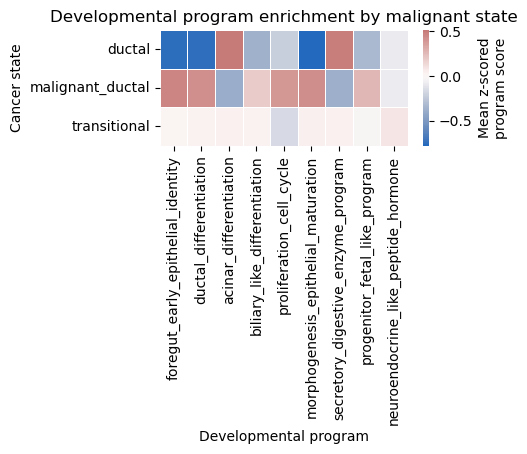

In [91]:
plt.figure(figsize=(4, max(1.5, 0.35 * state_dev_program_zmeans.shape[0])))

sns.heatmap(state_dev_program_zmeans,cmap="vlag",center=0,linewidths=0.5,cbar_kws={"label": "Mean z-scored\nprogram score"})

plt.yticks(rotation=0, ha="right") # rotation=0 makes them horizontal; ha="right" adjusts alignment
plt.title("Developmental program enrichment by malignant state")
plt.xlabel("Developmental program")
plt.ylabel("Cancer state")
plt.tight_layout()

fig_path = os.path.join(OUTDIR_c,"figures","state_developmental_program_heatmap.pdf")

os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path)
plt.show()

*State x cancer programs*
**What cancer programs does each state carry?**

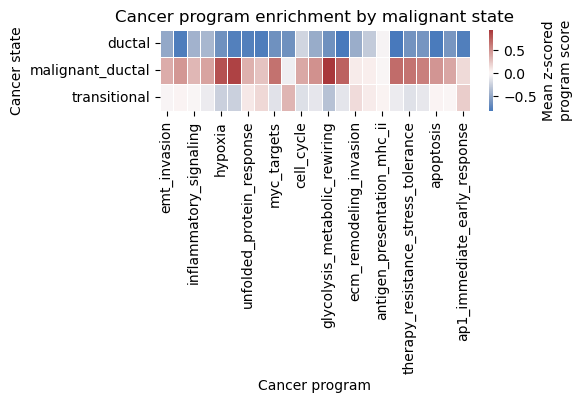

In [97]:
plt.figure(figsize=(5, min(5, 0.35 * state_cancer_program_zmeans.shape[0])))

sns.heatmap(state_cancer_program_zmeans,cmap="vlag",center=0,linewidths=0.5,cbar_kws={"label": "Mean z-scored\nprogram score"})

plt.yticks(rotation=0, ha="right") 
plt.title("Cancer program enrichment by malignant state")
plt.xlabel("Cancer program")
plt.ylabel("Cancer state")
#plt.tight_layout()

fig_path = os.path.join(OUTDIR_c,"figures","state_cancer_program_heatmap.pdf")
plt.savefig(fig_path)
plt.show()

*State x residual axis*
**Which residual malignant axes define each state?**

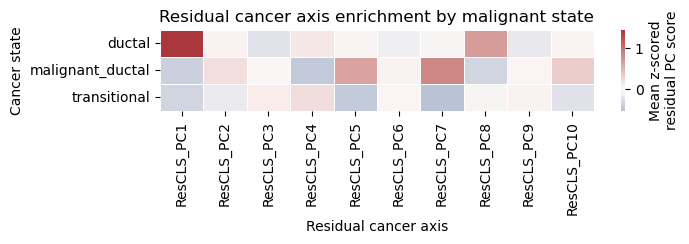

In [98]:
plt.figure(figsize=(7, min(4, 0.35 * state_res_axis_zmeans.shape[0])))

sns.heatmap(state_res_axis_zmeans,cmap="vlag",center=0,linewidths=0.5,cbar_kws={"label": "Mean z-scored\nresidual PC score"})

plt.yticks(rotation=0, ha="right") 
plt.title("Residual cancer axis enrichment by malignant state")
plt.xlabel("Residual cancer axis")
plt.ylabel("Cancer state")
#plt.tight_layout()

fig_path = os.path.join(OUTDIR_c,"figures","state_residual_axis_heatmap.pdf",)

plt.savefig(fig_path)
plt.show()

----

### 4. Biologically interpret malignant transition vectors

- Run transition vectors in *developmental PC* space to connect with the claim that malignant transitions do not follow normal developmental directions.
- Run the same transition vectors in *residual cancer* space to explain what cancer programs replace the developmental direction.

*some helper functions*

In [101]:
def fit_state_transition_vector(coords, states, start_state, end_state, n_dims=None):
    """
    Define a transition vector between two malignant state centroids.
        coords: cells x dimensions latent coordinate matrix
        states:one state label per cell
        start_state, end_state:labels defining the transition direction
        n_dims:number of latent dimensions to use. If None, use all dimensions.
    """
    coords = np.asarray(coords)
    states = np.asarray(states).astype(str)

    if n_dims is not None:
        X = coords[:, :n_dims]
    else:
        X = coords

    start_mask = states == str(start_state)
    end_mask = states == str(end_state)

    if start_mask.sum() == 0:
        raise ValueError(f"No cells found for start_state: {start_state}")

    if end_mask.sum() == 0:
        raise ValueError(f"No cells found for end_state: {end_state}")

    start_centroid = X[start_mask, :].mean(axis=0)
    end_centroid = X[end_mask, :].mean(axis=0)

    direction = end_centroid - start_centroid
    norm = np.linalg.norm(direction)

    if norm == 0:
        raise ValueError(f"Zero-length transition vector: {start_state} to {end_state}")

    unit_direction = direction / norm

    projection = (X - start_centroid) @ unit_direction

    return {
        "transition": f"{start_state}_to_{end_state}",
        "start_state": start_state,
        "end_state": end_state,
        "n_dims": X.shape[1],
        "projection": projection,
        "unit_direction": unit_direction,
        "start_centroid": start_centroid,
        "end_centroid": end_centroid,
    }

**Define transitions**

In [111]:
transition_specs = [
    ("ductal", "transitional"),
    ("transitional", "malignant_ductal"),
    ("ductal", "malignant_ductal"),
]

**THIS IS WHAT I GOT BEFORE**
- ductal label = acinar/secretory-like state
- transitional = neuroendocrine-like stress/adaptive state
- malignant_ductal = ductal/progenitor-like metabolic-stress state

**Run transition vectors in residual cancer space.**
This is the most relevant for “what malignant directions do they follow?”

In [115]:
# N_RES_DIMS_FOR_TRANSITIONS = 10 # BEFORE !!
N_RES_DIMS_FOR_TRANSITIONS = 30

transition_objects_res = {}

for start_state, end_state in transition_specs:
    obj = fit_state_transition_vector(coords=coords_canres,states=labels_can,start_state=start_state,end_state=end_state,n_dims=N_RES_DIMS_FOR_TRANSITIONS)

    transition_name = obj["transition"]
    transition_objects_res[transition_name] = obj

    adata_can.obs[f"TransRes_{transition_name}"] = obj["projection"]

print("Computed residual-space transition vectors:")
print(list(transition_objects_res.keys()))

Computed residual-space transition vectors:
['ductal_to_transitional', 'transitional_to_malignant_ductal', 'ductal_to_malignant_ductal']


**Run transition vectors in developmental cancer space.** This tells you how the same malignant transitions behave in the developmental coordinate system.

In [114]:
N_DEV_DIMS_FOR_TRANSITIONS = 75

transition_objects_dev = {}

for start_state, end_state in transition_specs:
    obj = fit_state_transition_vector(coords=Xc_pca,states=labels_can,start_state=start_state,end_state=end_state,n_dims=N_DEV_DIMS_FOR_TRANSITIONS,)

    transition_name = obj["transition"]
    transition_objects_dev[transition_name] = obj

    adata_can.obs[f"TransDev_{transition_name}"] = obj["projection"]

print("Computed developmental-space transition vectors:")
print(list(transition_objects_dev.keys()))

Computed developmental-space transition vectors:
['ductal_to_transitional', 'transitional_to_malignant_ductal', 'ductal_to_malignant_ductal']


**Correlate transition projections with genes.** Reuse your existing *gene_axis_correlations*.

In [116]:
OUTDIR_TRANS = os.path.join(OUTDIR_c, "malignant_transition_vectors")
os.makedirs(OUTDIR_TRANS, exist_ok=True)
os.makedirs(os.path.join(OUTDIR_TRANS, "gene_correlations"), exist_ok=True)
os.makedirs(os.path.join(OUTDIR_TRANS, "top_genes"), exist_ok=True)

transition_gene_tables = {}

# Residual-space transitions
for transition_name, obj in transition_objects_res.items():
    axis_name = f"TransRes_{transition_name}"
    projection = obj["projection"]

    corr_df = gene_axis_correlations(adata_can,projection,layer=LAYER,method=CORR_METHOD)

    corr_df["axis"] = axis_name
    corr_df["axis_type"] = "cancer_state_transition_residual_space"
    corr_df["start_state"] = obj["start_state"]
    corr_df["end_state"] = obj["end_state"]

    transition_gene_tables[axis_name] = corr_df

    corr_df.to_csv(os.path.join(OUTDIR_TRANS,"gene_correlations",f"{axis_name}_gene_correlations.csv"),index=False)

    corr_df.head(100).to_csv(os.path.join(OUTDIR_TRANS,"top_genes",f"{axis_name}_top_100_genes.csv"),index=False)


# Developmental-space transitions
for transition_name, obj in transition_objects_dev.items():
    axis_name = f"TransDev_{transition_name}"
    projection = obj["projection"]

    corr_df = gene_axis_correlations(adata_can,projection,layer=LAYER,method=CORR_METHOD)

    corr_df["axis"] = axis_name
    corr_df["axis_type"] = "cancer_state_transition_developmental_space"
    corr_df["start_state"] = obj["start_state"]
    corr_df["end_state"] = obj["end_state"]

    transition_gene_tables[axis_name] = corr_df

    corr_df.to_csv(os.path.join(OUTDIR_TRANS,"gene_correlations",f"{axis_name}_gene_correlations.csv"),index=False)

    corr_df.head(100).to_csv(os.path.join(OUTDIR_TRANS,"top_genes",f"{axis_name}_top_100_genes.csv"),index=False)

print("Finished gene correlations for malignant transition vectors.")

Finished gene correlations for malignant transition vectors.


**Correlate transition projections with developmental and cancer programs**

We already have computed: *dev_program_scores_can* and *cancer_program_scores*

In [117]:
# make sure they are aligned
assert dev_program_scores_can.shape[0] == adata_can.n_obs
assert cancer_program_scores.shape[0] == adata_can.n_obs

all transition projections

In [118]:
transition_axis_values = {}

for transition_name, obj in transition_objects_res.items():
    transition_axis_values[f"TransRes_{transition_name}"] = obj["projection"]

for transition_name, obj in transition_objects_dev.items():
    transition_axis_values[f"TransDev_{transition_name}"] = obj["projection"]

Correlate with **developmental programs**

In [119]:
transition_dev_program_corr = correlate_program_scores(transition_axis_values,dev_program_scores_can)
transition_dev_program_corr.to_csv(os.path.join(OUTDIR_TRANS, "transition_developmental_program_correlations.csv"),index=False)

transition_dev_program_corr_matrix = transition_dev_program_corr.pivot(index="program",columns="axis",values="spearman_r")
transition_dev_program_corr_matrix.to_csv(os.path.join(OUTDIR_TRANS, "transition_developmental_program_correlation_matrix.csv"))

transition_dev_program_corr_matrix

axis,TransDev_ductal_to_malignant_ductal,TransDev_ductal_to_transitional,TransDev_transitional_to_malignant_ductal,TransRes_ductal_to_malignant_ductal,TransRes_ductal_to_transitional,TransRes_transitional_to_malignant_ductal
program,,,,,,
acinar_differentiation,-0.787099,-0.236400,-0.563630,-0.683752,-0.288414,-0.577392
biliary_like_differentiation,0.593821,0.564457,0.102178,0.518101,0.518544,-0.001974
ductal_differentiation,0.777442,0.649370,0.171690,0.737100,0.638299,0.122162
foregut_early_epithelial_identity,0.805445,0.636206,0.215430,0.762582,0.621518,0.206691
morphogenesis_epithelial_maturation,0.796625,0.654108,0.193218,0.755207,0.637772,0.171341
neuroendocrine_like_peptide_hormone,0.049186,0.348109,-0.339217,0.108346,0.335360,-0.382648
progenitor_fetal_like_program,0.630744,0.289747,0.395365,0.483044,0.275497,0.275470
proliferation_cell_cycle,0.652981,0.341538,0.319551,0.613925,0.363865,0.333839
secretory_digestive_enzyme_program,-0.760163,-0.247324,-0.520074,-0.674468,-0.309255,-0.524086


Correlate with **cancer programs**

In [120]:
transition_cancer_program_corr = correlate_program_scores(transition_axis_values,cancer_program_scores)
transition_cancer_program_corr.to_csv(os.path.join(OUTDIR_TRANS, "transition_cancer_program_correlations.csv"),index=False)

transition_cancer_program_corr_matrix = transition_cancer_program_corr.pivot(index="program",columns="axis",values="spearman_r")
transition_cancer_program_corr_matrix.to_csv(os.path.join(OUTDIR_TRANS, "transition_cancer_program_correlation_matrix.csv"))

transition_cancer_program_corr_matrix

axis,TransDev_ductal_to_malignant_ductal,TransDev_ductal_to_transitional,TransDev_transitional_to_malignant_ductal,TransRes_ductal_to_malignant_ductal,TransRes_ductal_to_transitional,TransRes_transitional_to_malignant_ductal
program,,,,,,
antigen_presentation_mhc_i,0.390715,0.509273,-0.103725,0.432394,0.513985,-0.122365
antigen_presentation_mhc_ii,-0.030847,0.197230,-0.240836,0.063278,0.209416,-0.204228
ap1_immediate_early_response,0.498732,0.708457,-0.219851,0.626858,0.733211,-0.206528
apoptosis,0.746048,0.588027,0.196359,0.732871,0.599200,0.174486
cell_cycle,0.665846,0.345336,0.328511,0.624824,0.368225,0.343056
dna_damage_repair,0.624936,0.427072,0.204976,0.618689,0.453927,0.207254
ecm_remodeling_invasion,0.750462,0.540367,0.258981,0.651137,0.473512,0.261363
emt_invasion,0.778901,0.457016,0.363998,0.658613,0.413525,0.352974
epithelial_identity,0.802918,0.648876,0.204392,0.757214,0.632407,0.180537


>Transition heatmaps

**Developmental programs along transitions**

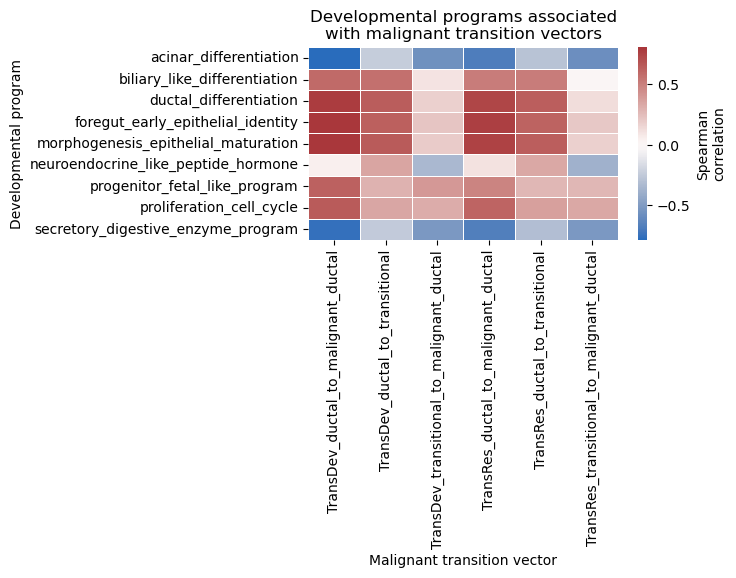

/home/jfpoyatos/Work/MNCN_24_25/A - plasticity - What's next/scripts/data/Mouse/annotation_malignant_residual_axes/malignant_transition_vectors/transition_developmental_program_heatmap.pdf


In [121]:
plt.figure(figsize=(5, min(2.5, 0.35 * transition_dev_program_corr_matrix.shape[0])))

sns.heatmap(transition_dev_program_corr_matrix,cmap="vlag",center=0,linewidths=0.5,cbar_kws={"label": "Spearman\ncorrelation"})
plt.title("Developmental programs associated\nwith malignant transition vectors")
plt.xlabel("Malignant transition vector")
plt.ylabel("Developmental program")
#plt.tight_layout()

fig_path = os.path.join(OUTDIR_TRANS,"transition_developmental_program_heatmap.pdf")

plt.savefig(fig_path)
plt.show()
print(fig_path)

**Cancer programs along transitions**

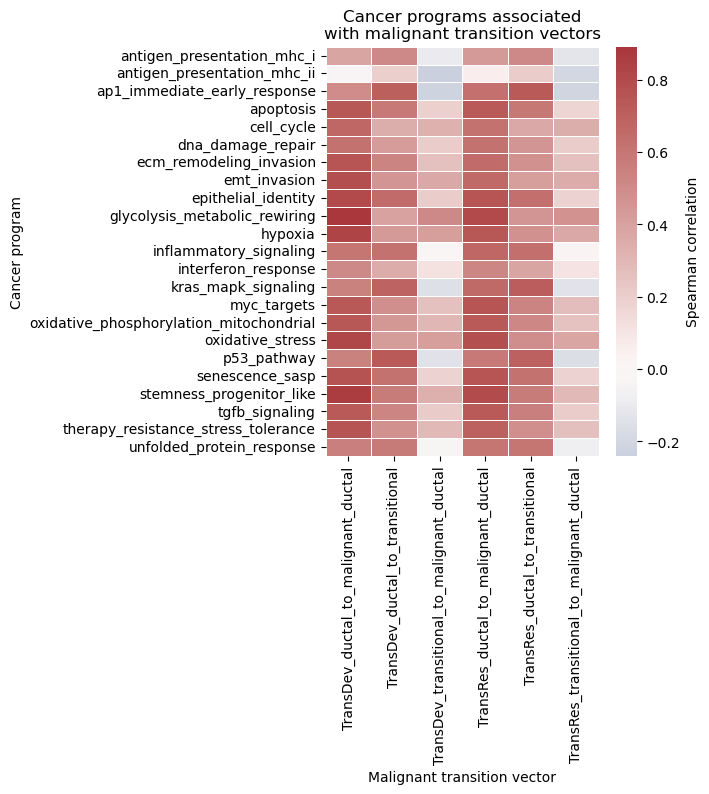

/home/jfpoyatos/Work/MNCN_24_25/A - plasticity - What's next/scripts/data/Mouse/annotation_malignant_residual_axes/malignant_transition_vectors/transition_cancer_program_heatmap.pdf


In [122]:
plt.figure(figsize=(7, max(4, 0.35 * transition_cancer_program_corr_matrix.shape[0])))

sns.heatmap(transition_cancer_program_corr_matrix,cmap="vlag",center=0,linewidths=0.5,cbar_kws={"label": "Spearman correlation"})
plt.title("Cancer programs associated\nwith malignant transition vectors")
plt.xlabel("Malignant transition vector")
plt.ylabel("Cancer program")
plt.tight_layout()

fig_path = os.path.join(OUTDIR_TRANS,"transition_cancer_program_heatmap.pdf")

plt.savefig(fig_path)
plt.show()

print(fig_path)

**Compact transition sumary table**

In [123]:
summary_rows = []

for axis_name, corr_df in transition_gene_tables.items():
    top_positive_genes = (
        corr_df.sort_values("correlation", ascending=False)
        .head(15)["gene"]
        .astype(str)
        .tolist()
    )

    top_negative_genes = (
        corr_df.sort_values("correlation", ascending=True)
        .head(15)["gene"]
        .astype(str)
        .tolist()
    )

    top_dev_programs = (
        transition_dev_program_corr[transition_dev_program_corr["axis"] == axis_name]
        .sort_values("abs_spearman_r", ascending=False)
        .head(5)
    )

    top_cancer_programs = (
        transition_cancer_program_corr[transition_cancer_program_corr["axis"] == axis_name]
        .sort_values("abs_spearman_r", ascending=False)
        .head(7)
    )

    summary_rows.append({
        "transition_axis": axis_name,
        "axis_type": corr_df["axis_type"].iloc[0],
        "start_state": corr_df["start_state"].iloc[0],
        "end_state": corr_df["end_state"].iloc[0],
        "top_positive_genes": ", ".join(top_positive_genes),
        "top_negative_genes": ", ".join(top_negative_genes),
        "top_developmental_programs": "; ".join(
            [f"{row.program}: r={row.spearman_r:.2f}" for row in top_dev_programs.itertuples()]
        ),
        "top_cancer_programs": "; ".join(
            [f"{row.program}: r={row.spearman_r:.2f}" for row in top_cancer_programs.itertuples()]
        ),
    })

transition_summary = pd.DataFrame(summary_rows)

transition_summary.to_csv(
    os.path.join(OUTDIR_TRANS, "malignant_transition_vector_annotation_summary.csv"),
    index=False,
)

transition_summary

,transition_axis,axis_type,start_state,end_state,top_positive_genes,top_negative_genes,top_developmental_programs,top_cancer_programs
0,TransRes_ductal_to_transitional,cancer_state_transition_residual_space,ductal,transitional,"Ddx5, Morf4l1, Eef1a1, Ubb, Tmem59, H3f3b, Spi...","Zg16, Cela1, Rnase1, Pnlip, Pla2g1b, Ctrl, Try...",ductal_differentiation: r=0.64; morphogenesis_...,ap1_immediate_early_response: r=0.73; kras_map...
1,TransRes_transitional_to_malignant_ductal,cancer_state_transition_residual_space,transitional,malignant_ductal,"Gapdh, Wfdc2, Aprt, S100a6, Pkm, Tpi1, Fau, To...","C4b, Elapor1, Tmem45a, Slc12a8, Dmbt1, Fam174b...",acinar_differentiation: r=-0.58; secretory_dig...,glycolysis_metabolic_rewiring: r=0.47; oxidati...
2,TransRes_ductal_to_malignant_ductal,cancer_state_transition_residual_space,ductal,malignant_ductal,"Eef1a1, Ubb, Laptm4a, Eif1, Cox4i1, Akr1a1, Tb...","Zg16, Rnase1, Cela1, Ctrl, Pnlip, Pla2g1b, Try...",foregut_early_epithelial_identity: r=0.76; mor...,glycolysis_metabolic_rewiring: r=0.80; stemnes...
3,TransDev_ductal_to_transitional,cancer_state_transition_developmental_space,ductal,transitional,"Ddx5, Klf6, Cd81, H3f3b, Morf4l1, Spint2, Ubb,...","Zg16, Rnase1, Cela1, Ctrl, Try4, Pnlip, Pla2g1...",morphogenesis_epithelial_maturation: r=0.65; d...,p53_pathway: r=0.73; ap1_immediate_early_respo...
4,TransDev_transitional_to_malignant_ductal,cancer_state_transition_developmental_space,transitional,malignant_ductal,"S100a6, Pkm, Gapdh, Capg, Aprt, Tpi1, Cdkn2a, ...","C4b, Tmem45a, Slc12a8, Elapor1, Gstt1, Jun, Pa...",acinar_differentiation: r=-0.56; secretory_dig...,glycolysis_metabolic_rewiring: r=0.51; hypoxia...
5,TransDev_ductal_to_malignant_ductal,cancer_state_transition_developmental_space,ductal,malignant_ductal,"Cd9, Tspo, Arpc2, Gnb2, Capns1, Tpm3, Rhoa, Yw...","Rnase1, Clps, Zg16, Cela3b, Cpa2, Ctrl, Cela1,...",foregut_early_epithelial_identity: r=0.81; mor...,glycolysis_metabolic_rewiring: r=0.89; stemnes...


**Optional: compare malignant transition vectors to developmental directions**

This directly tests whether malignant transitions follow normal developmental axes.

you have
- lineage_direction_objects, and 
- transition_objects_dev

*compute cosine similarity*

In [214]:
cosine_rows = []

for trans_name, trans_obj in transition_objects_dev.items():
    trans_vec = trans_obj["unit_direction"]

    for lineage_name, lineage_obj in lineage_direction_objects.items():
        lin_vec = lineage_obj["unit_direction"]

        n = min(len(trans_vec), len(lin_vec))

        cosine = np.dot(trans_vec[:n], lin_vec[:n]) / (
            np.linalg.norm(trans_vec[:n]) * np.linalg.norm(lin_vec[:n])
        )

        cosine_rows.append({
            "transition": trans_name,
            "lineage_direction": lineage_name,
            "cosine_similarity": cosine,
            "abs_cosine_similarity": abs(cosine),
        })

transition_lineage_cosine = pd.DataFrame(cosine_rows)

transition_lineage_cosine.to_csv(
    os.path.join(OUTDIR_TRANS, "transition_vs_developmental_direction_cosine_similarity.csv"),
    index=False,
)

transition_lineage_cosine.sort_values(
    ["transition", "abs_cosine_similarity"],
    ascending=[True, False],
)

,transition,lineage_direction,cosine_similarity,abs_cosine_similarity
7,ductal_to_malignant_ductal,foregut_to_acinar,-0.204080,0.204080
6,ductal_to_malignant_ductal,foregut_to_ductal,0.137273,0.137273
8,ductal_to_malignant_ductal,foregut_to_biliary,0.102329,0.102329
1,ductal_to_transitional,foregut_to_acinar,-0.249413,0.249413
2,ductal_to_transitional,foregut_to_biliary,0.035476,0.035476
0,ductal_to_transitional,foregut_to_ductal,0.007865,0.007865
3,transitional_to_malignant_ductal,foregut_to_ductal,0.175678,0.175678
5,transitional_to_malignant_ductal,foregut_to_biliary,0.095147,0.095147
4,transitional_to_malignant_ductal,foregut_to_acinar,0.026297,0.026297


**Optional: project only cells from the two endpoint states**

- For the main correlation, I projected **all** cancer cells onto the transition vector. That gives global structure.

- But you can also run a restricted version using only cells from the start and end states to get endpoint-specific markers.

In [ ]:
def subset_axis_values(axis_values, mask):
    return np.asarray(axis_values)[mask]


transition_endpoint_gene_tables = {}

for transition_name, obj in transition_objects_res.items():
    start_state = obj["start_state"]
    end_state = obj["end_state"]

    endpoint_mask = np.isin(labels_can, [start_state, end_state])

    adata_sub = adata_can[endpoint_mask].copy()
    projection_sub = obj["projection"][endpoint_mask]

    axis_name = f"TransRes_{transition_name}_endpoint_only"

    corr_df = gene_axis_correlations(
        adata_sub,
        projection_sub,
        layer=LAYER,
        method=CORR_METHOD,
    )

    corr_df["axis"] = axis_name
    corr_df["axis_type"] = "endpoint_only_cancer_state_transition_residual_space"
    corr_df["start_state"] = start_state
    corr_df["end_state"] = end_state

    transition_endpoint_gene_tables[axis_name] = corr_df

In [216]:
corr_df

,gene,correlation,abs_correlation,axis,axis_type,start_state,end_state
11522,Zg16,-0.680239,0.680239,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
7183,Cox4i1,0.670859,0.670859,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
9026,Eef1a1,0.669047,0.669047,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
9214,Fau,0.666065,0.666065,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
2770,Btf3,0.659462,0.659462,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
...,...,...,...,...,...,...,...
1929,Il20ra,0.000000,0.000000,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
14413,Gm12022,0.000000,0.000000,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
7599,Col6a4,0.000000,0.000000,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
4308,Bsnd,0.000000,0.000000,TransRes_ductal_to_malignant_ductal_endpoint_only,endpoint_only_cancer_state_transition_residual...,ductal,malignant_ductal
